**Projet : Prédiction de la demande potentielle en retail alimentaire**

**Installation des bibliothèques nécessaires**

In [16]:
%pip install datasets pyarrow pandas numpy lightgbm xgboost scikit-learn shap

Note: you may need to restart the kernel to use updated packages.


error: externally-managed-environment

× This environment is externally managed
╰─> This Python installation is managed by uv and should not be modified.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.


In [17]:
# Bibliothèques de base
import pandas as pd
import numpy as np
from datasets import load_dataset

# Prétraitement et pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


# Séparation train/test
from sklearn.model_selection import train_test_split

# Modèle MLP
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor

# Évaluation
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error


# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

**Chargement du dataset FreshRetailNet-50K depuis Hugging Face**

In [18]:
ds = load_dataset("Dingdong-Inc/FreshRetailNet-50K")

**Nettoyage des données : filtrage des villes**

In [19]:
# Convert to pandas DataFrames
train_df = ds['train'].to_pandas()
eval_df = ds['eval'].to_pandas()

city_ids_to_remove = [0,16,12,3]
# Nombre de lignes avant suppression
print("Nombre total avant :", len(train_df))

# Suppression
train_df = train_df[~train_df['city_id'].isin(city_ids_to_remove)].copy()
eval_df = eval_df[~eval_df['city_id'].isin(city_ids_to_remove)].copy()

# Nombre de lignes après suppression
print("Nombre total après :", len(train_df))

Nombre total avant : 4500000
Nombre total après : 1070640


**Exploration et compréhension des données**


Training set shape: (1070640, 19)
Evaluation set shape: (83272, 19)

train_df:
  Rows: 1,070,640 | Cities: 14 | Stores: 311 | Products: 544
  Period: 2024-03-28 00:00:00 -> 2024-06-25 00:00:00
  Stockout rate: 45.165%

eval_df:
  Rows: 83,272 | Cities: 14 | Stores: 311 | Products: 544
  Period: 2024-06-26 00:00:00 -> 2024-07-02 00:00:00
  Stockout rate: 40.358%

1. ANALYSE GEOGRAPHIQUE


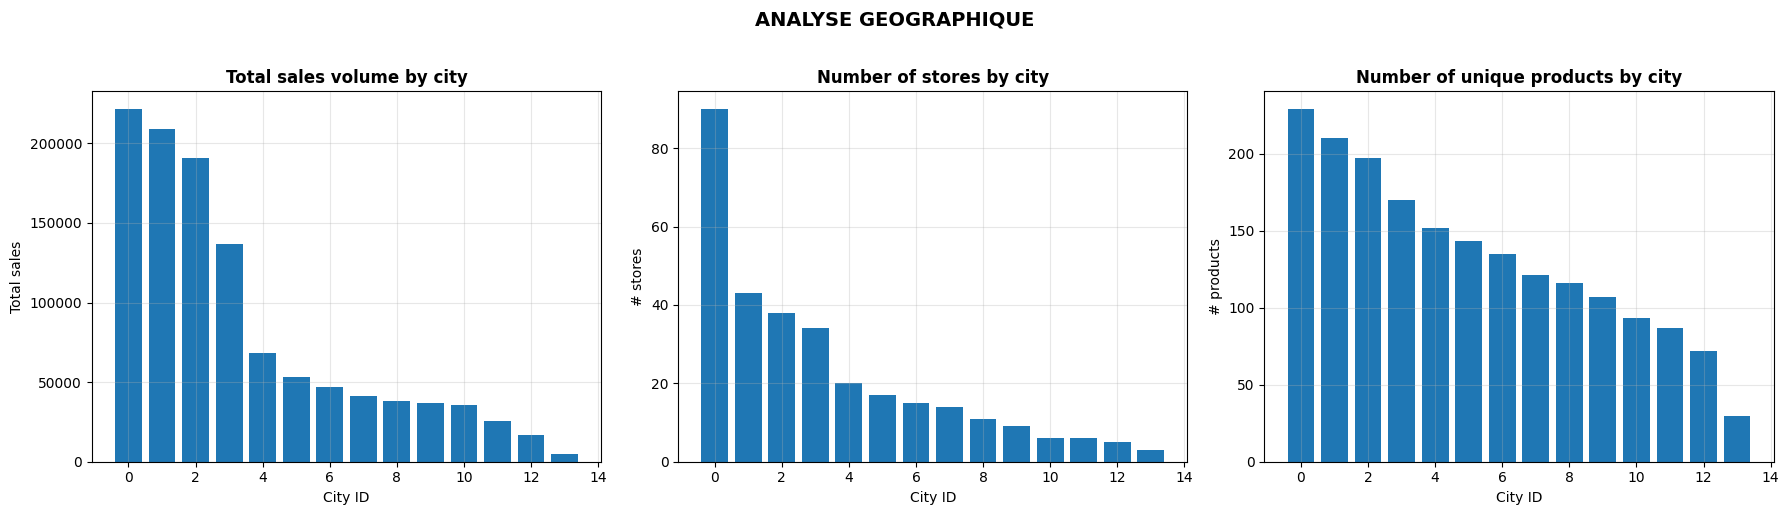


2. ANALYSE TEMPORELLE


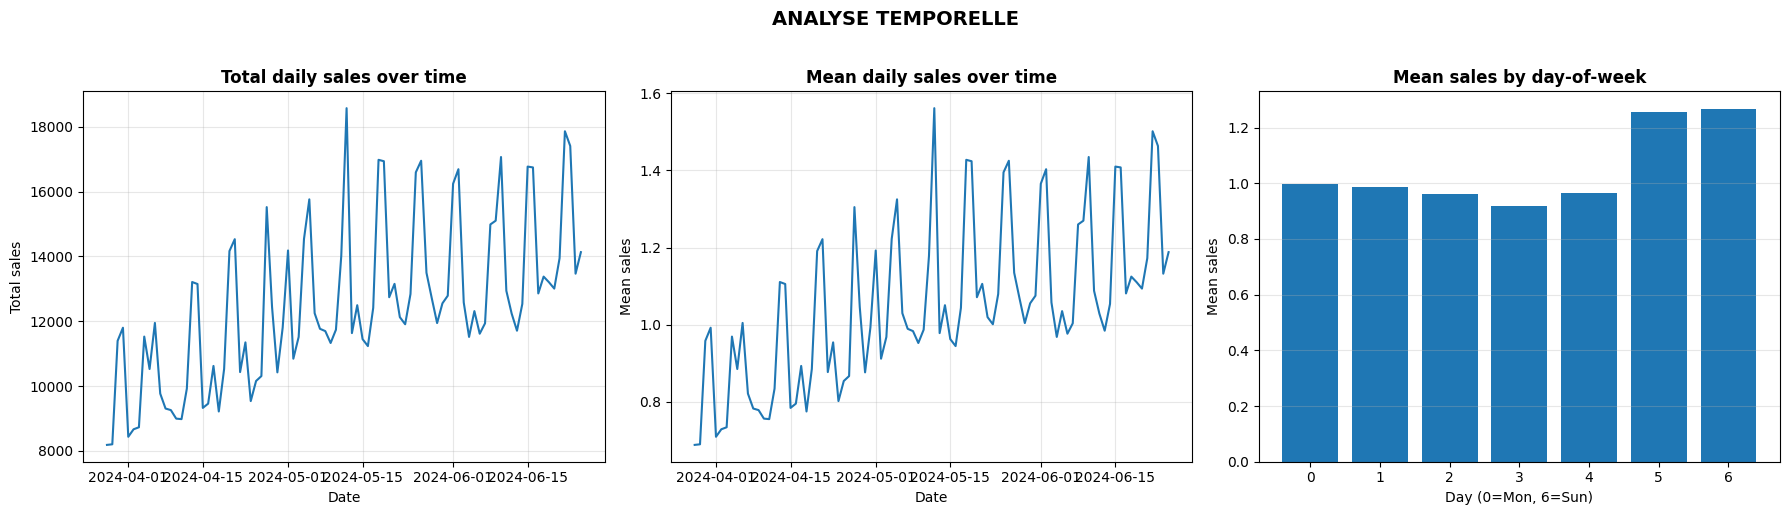


3. RUPTURES ET DISPONIBILITE


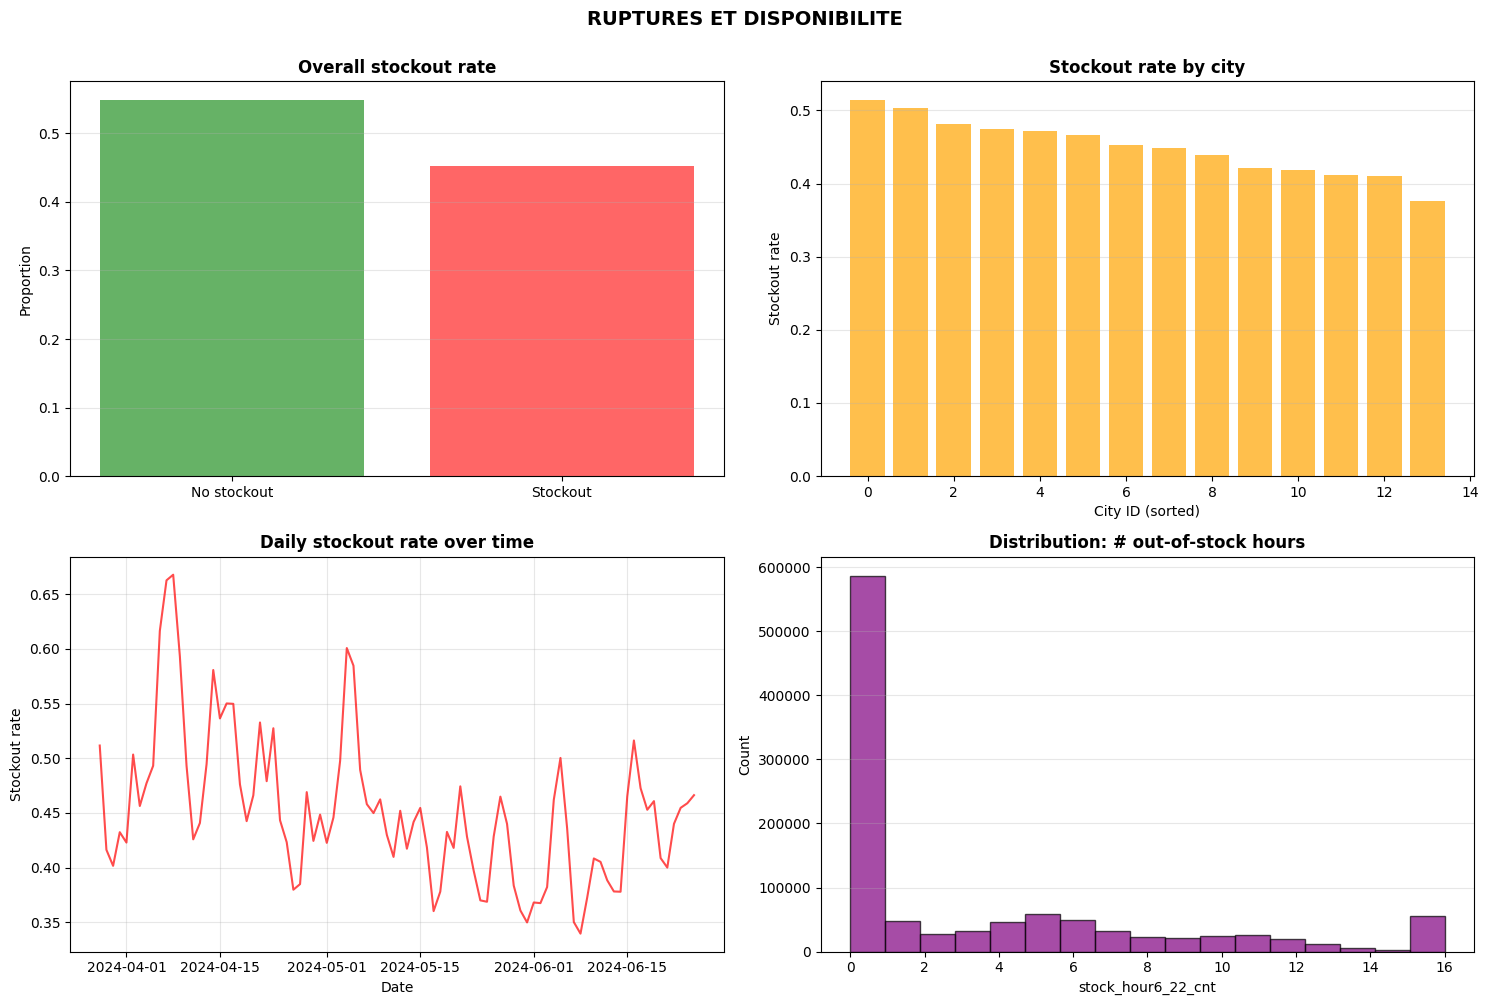


4. RUPTURE VS DEMANDE


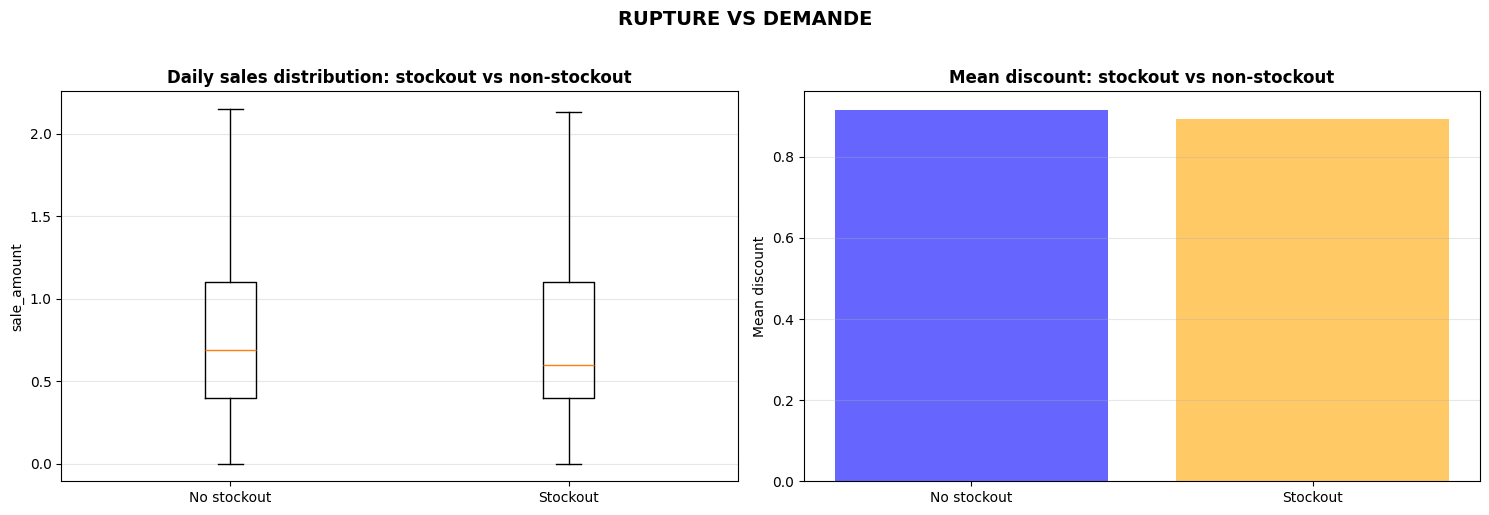


5. PROMOTIONS ET CONTEXTE


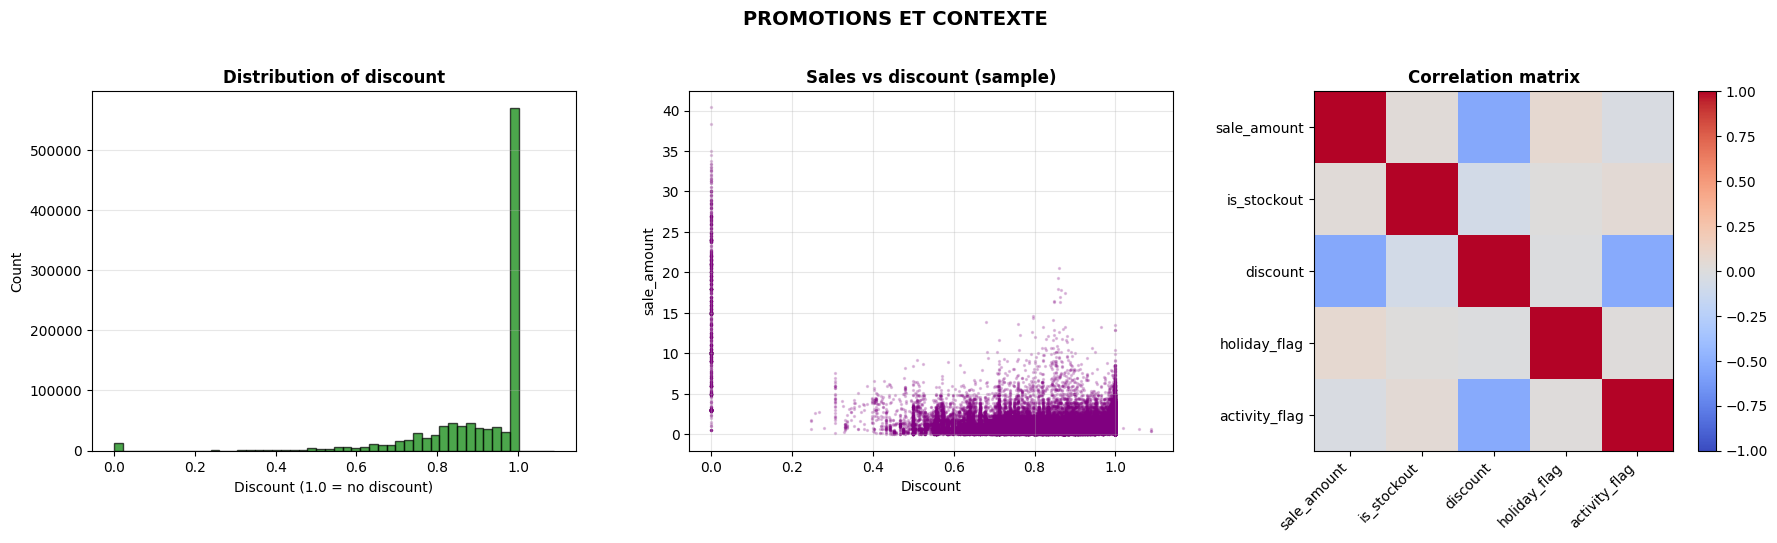


6. IMPACT HOLIDAY & ACTIVITY


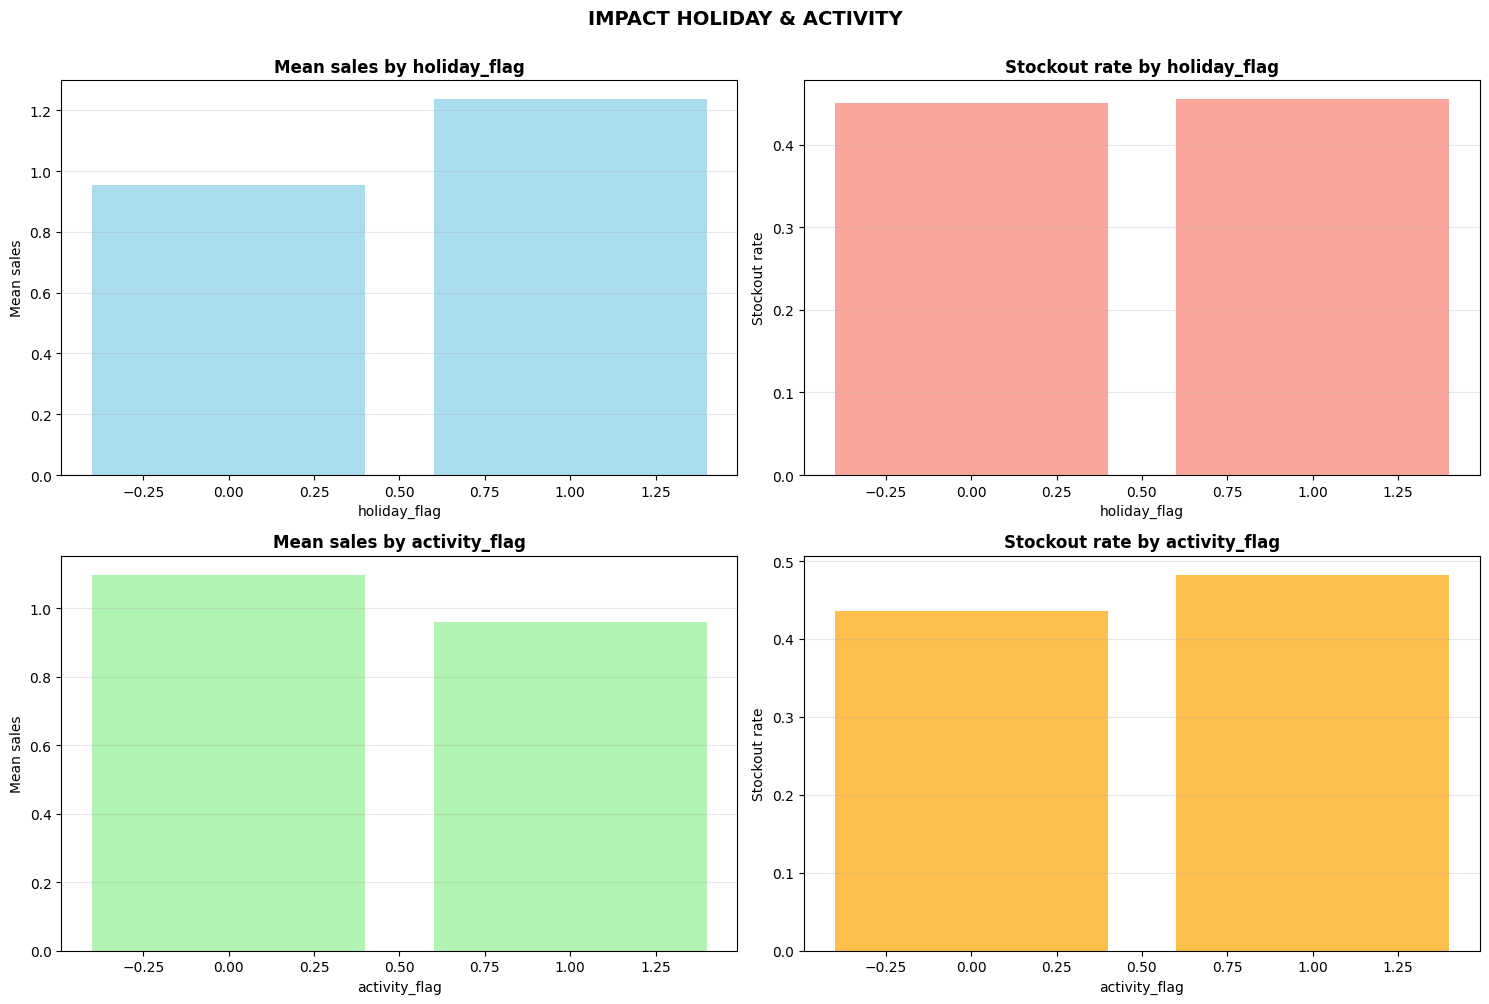


7. PROFILS HORAIRES


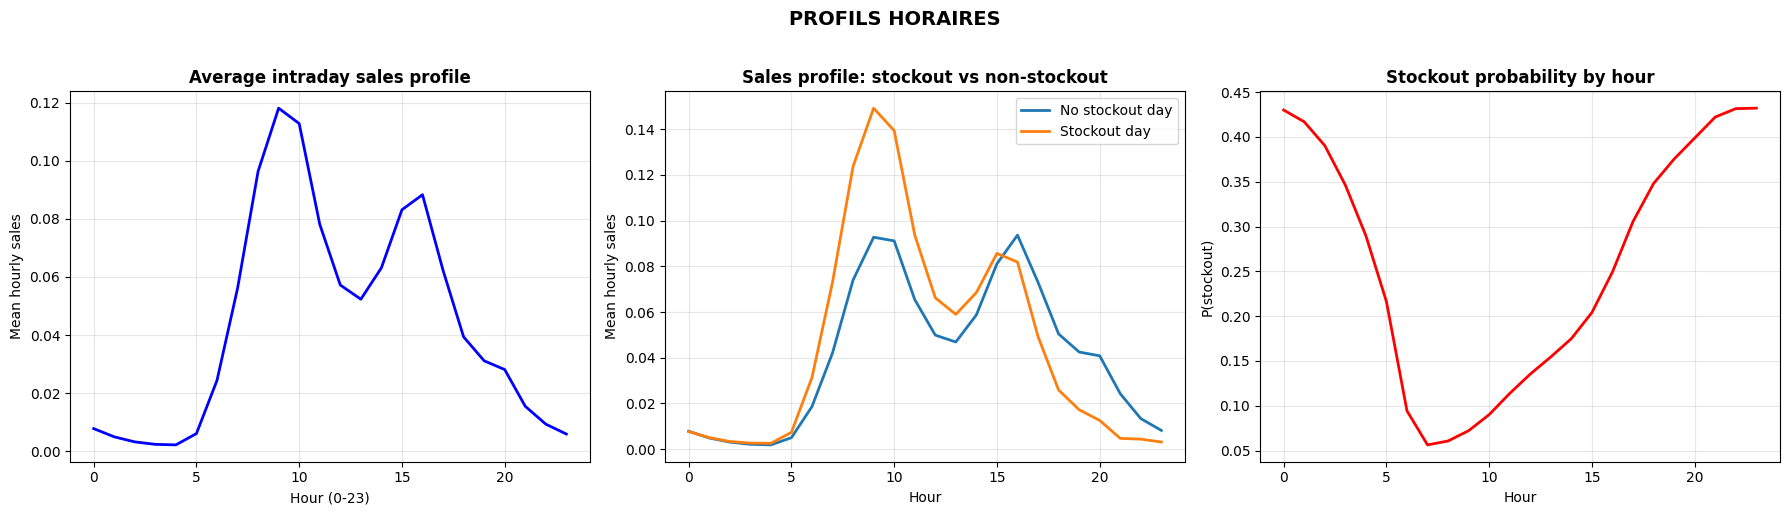


8. HETEROGENEITE PRODUITS/MAGASINS


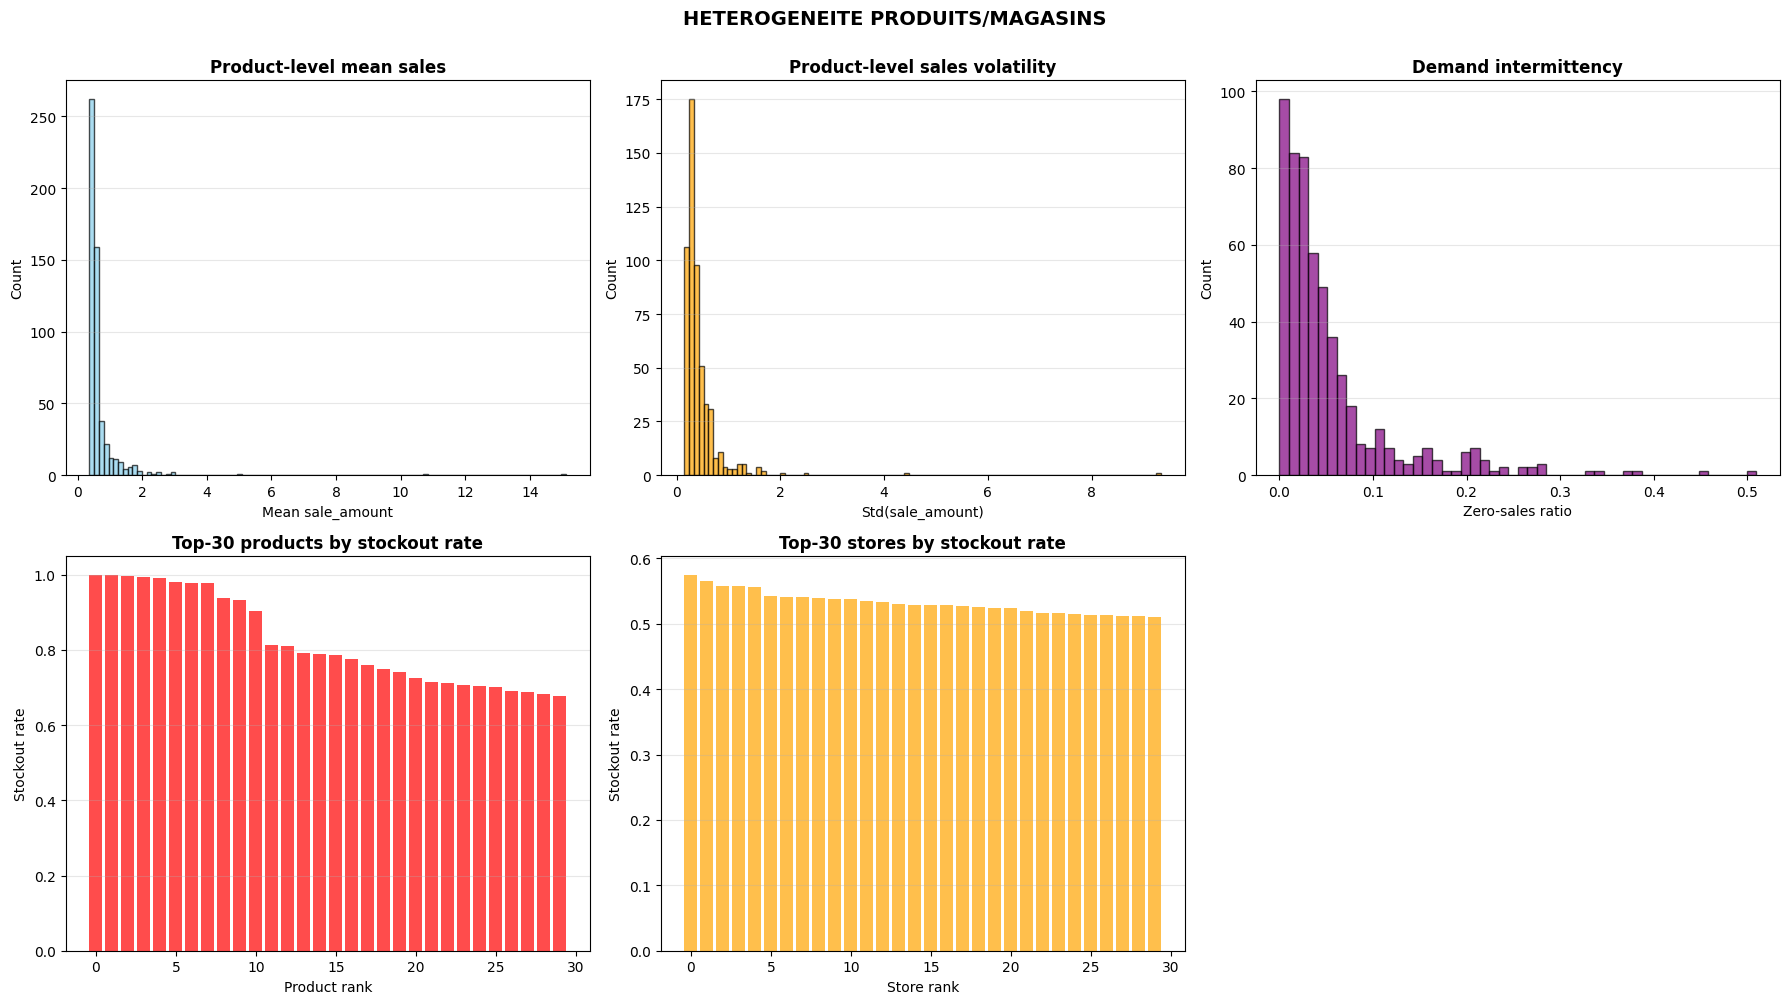

In [20]:
# Configuration globale
plt.rcParams['figure.figsize'] = (15, 5)
plt.rcParams['font.size'] = 10
PLOT_SAMPLE_N = 100000
RANDOM_SEED = 42

print(f"\nTraining set shape: {train_df.shape}")
print(f"Evaluation set shape: {eval_df.shape}")

for df in (train_df, eval_df):
    df["dt"] = pd.to_datetime(df["dt"])
    df["is_stockout"] = (df["stock_hour6_22_cnt"] > 0).astype(np.int8)
    df["dow"] = df["dt"].dt.dayofweek

def overview(df, name="train"):
    print(f"\n{name}:")
    print(f"  Rows: {len(df):,} | Cities: {df['city_id'].nunique()} | Stores: {df['store_id'].nunique()} | Products: {df['product_id'].nunique()}")
    print(f"  Period: {df['dt'].min()} -> {df['dt'].max()}")
    print(f"  Stockout rate: {df['is_stockout'].mean():.3%}")

overview(train_df, "train_df")
overview(eval_df, "eval_df")

print("\n" + "="*80)
print("1. ANALYSE GEOGRAPHIQUE")
print("="*80)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Ventes par ville
city_sales = train_df.groupby("city_id")["sale_amount"].sum().sort_values(ascending=False)
axes[0].bar(range(len(city_sales)), city_sales.values)
axes[0].set_title("Total sales volume by city", fontweight='bold')
axes[0].set_xlabel("City ID")
axes[0].set_ylabel("Total sales")
axes[0].grid(True, alpha=0.3)

# Magasins par ville
stores_by_city = train_df.groupby("city_id")["store_id"].nunique().sort_values(ascending=False)
axes[1].bar(range(len(stores_by_city)), stores_by_city.values)
axes[1].set_title("Number of stores by city", fontweight='bold')
axes[1].set_xlabel("City ID")
axes[1].set_ylabel("# stores")
axes[1].grid(True, alpha=0.3)

# Produits par ville
products_by_city = train_df.groupby("city_id")["product_id"].nunique().sort_values(ascending=False)
axes[2].bar(range(len(products_by_city)), products_by_city.values)
axes[2].set_title("Number of unique products by city", fontweight='bold')
axes[2].set_xlabel("City ID")
axes[2].set_ylabel("# products")
axes[2].grid(True, alpha=0.3)

plt.suptitle("ANALYSE GEOGRAPHIQUE", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("2. ANALYSE TEMPORELLE")
print("="*80)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Ventes totales par jour
daily_total_sales = train_df.groupby("dt")["sale_amount"].sum()
axes[0].plot(daily_total_sales.index, daily_total_sales.values)
axes[0].set_title("Total daily sales over time", fontweight='bold')
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Total sales")
axes[0].grid(True, alpha=0.3)

# Ventes moyennes par jour
daily_mean_sales = train_df.groupby("dt")["sale_amount"].mean()
axes[1].plot(daily_mean_sales.index, daily_mean_sales.values)
axes[1].set_title("Mean daily sales over time", fontweight='bold')
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Mean sales")
axes[1].grid(True, alpha=0.3)

# Pattern hebdomadaire
dow_sales = train_df.groupby("dow")["sale_amount"].mean()
axes[2].bar(dow_sales.index, dow_sales.values)
axes[2].set_title("Mean sales by day-of-week", fontweight='bold')
axes[2].set_xlabel("Day (0=Mon, 6=Sun)")
axes[2].set_ylabel("Mean sales")
axes[2].grid(True, alpha=0.3, axis='y')

plt.suptitle("ANALYSE TEMPORELLE", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print("\n" + "="*80)
print("3. RUPTURES ET DISPONIBILITE")
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Taux global de rupture
stockout_rate = train_df["is_stockout"].mean()
axes[0, 0].bar(["No stockout", "Stockout"], [1-stockout_rate, stockout_rate], color=['green', 'red'], alpha=0.6)
axes[0, 0].set_title("Overall stockout rate", fontweight='bold')
axes[0, 0].set_ylabel("Proportion")
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Taux de rupture par ville
city_stockout = train_df.groupby("city_id")["is_stockout"].mean().sort_values(ascending=False)
axes[0, 1].bar(range(len(city_stockout)), city_stockout.values, color='orange', alpha=0.7)
axes[0, 1].set_title("Stockout rate by city", fontweight='bold')
axes[0, 1].set_xlabel("City ID (sorted)")
axes[0, 1].set_ylabel("Stockout rate")
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Taux de rupture dans le temps
daily_stockout_rate = train_df.groupby("dt")["is_stockout"].mean()
axes[1, 0].plot(daily_stockout_rate.index, daily_stockout_rate.values, color='red', alpha=0.7)
axes[1, 0].set_title("Daily stockout rate over time", fontweight='bold')
axes[1, 0].set_xlabel("Date")
axes[1, 0].set_ylabel("Stockout rate")
axes[1, 0].grid(True, alpha=0.3)

# Distribution heures de rupture
axes[1, 1].hist(train_df["stock_hour6_22_cnt"], bins=17, color='purple', alpha=0.7, edgecolor='black')
axes[1, 1].set_title("Distribution: # out-of-stock hours", fontweight='bold')
axes[1, 1].set_xlabel("stock_hour6_22_cnt")
axes[1, 1].set_ylabel("Count")
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.suptitle("RUPTURES ET DISPONIBILITE", fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("4. RUPTURE VS DEMANDE")
print("="*80)

sample_df = train_df.sample(n=min(PLOT_SAMPLE_N, len(train_df)), random_state=RANDOM_SEED)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Boxplot ventes par statut rupture
data_boxplot = [
    sample_df.loc[sample_df["is_stockout"]==0, "sale_amount"].dropna(),
    sample_df.loc[sample_df["is_stockout"]==1, "sale_amount"].dropna()
]
axes[0].boxplot(data_boxplot, tick_labels=["No stockout","Stockout"], showfliers=False)
axes[0].set_title("Daily sales distribution: stockout vs non-stockout", fontweight='bold')
axes[0].set_ylabel("sale_amount")
axes[0].grid(True, alpha=0.3, axis='y')

# Discount moyen par statut
disc_by_stockout = train_df.groupby("is_stockout")["discount"].mean()
axes[1].bar(["No stockout", "Stockout"], disc_by_stockout.values, color=['blue', 'orange'], alpha=0.6)
axes[1].set_title("Mean discount: stockout vs non-stockout", fontweight='bold')
axes[1].set_ylabel("Mean discount")
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle("RUPTURE VS DEMANDE", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("5. PROMOTIONS ET CONTEXTE")
print("="*80)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution discount
axes[0].hist(train_df["discount"].dropna(), bins=50, color='green', alpha=0.7, edgecolor='black')
axes[0].set_title("Distribution of discount", fontweight='bold')
axes[0].set_xlabel("Discount (1.0 = no discount)")
axes[0].set_ylabel("Count")
axes[0].grid(True, alpha=0.3, axis='y')

# Ventes vs discount
axes[1].scatter(sample_df["discount"], sample_df["sale_amount"], s=2, alpha=0.2, c='purple')
axes[1].set_title("Sales vs discount (sample)", fontweight='bold')
axes[1].set_xlabel("Discount")
axes[1].set_ylabel("sale_amount")
axes[1].grid(True, alpha=0.3)

# Correlation matrix
corr_cols = ["sale_amount", "is_stockout", "discount", "holiday_flag", "activity_flag"]
corr = train_df[corr_cols].corr(numeric_only=True)
im = axes[2].imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
axes[2].set_xticks(range(len(corr.columns)))
axes[2].set_yticks(range(len(corr.index)))
axes[2].set_xticklabels(corr.columns, rotation=45, ha='right')
axes[2].set_yticklabels(corr.index)
axes[2].set_title("Correlation matrix", fontweight='bold')
plt.colorbar(im, ax=axes[2])

plt.suptitle("PROMOTIONS ET CONTEXTE", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("6. IMPACT HOLIDAY & ACTIVITY")
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Holiday: ventes et ruptures
holiday_sales = train_df.groupby("holiday_flag")["sale_amount"].mean()
holiday_stockout = train_df.groupby("holiday_flag")["is_stockout"].mean()

axes[0, 0].bar(holiday_sales.index, holiday_sales.values, color='skyblue', alpha=0.7)
axes[0, 0].set_title("Mean sales by holiday_flag", fontweight='bold')
axes[0, 0].set_xlabel("holiday_flag")
axes[0, 0].set_ylabel("Mean sales")
axes[0, 0].grid(True, alpha=0.3, axis='y')

axes[0, 1].bar(holiday_stockout.index, holiday_stockout.values, color='salmon', alpha=0.7)
axes[0, 1].set_title("Stockout rate by holiday_flag", fontweight='bold')
axes[0, 1].set_xlabel("holiday_flag")
axes[0, 1].set_ylabel("Stockout rate")
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Activity: ventes et ruptures
activity_sales = train_df.groupby("activity_flag")["sale_amount"].mean()
activity_stockout = train_df.groupby("activity_flag")["is_stockout"].mean()

axes[1, 0].bar(activity_sales.index, activity_sales.values, color='lightgreen', alpha=0.7)
axes[1, 0].set_title("Mean sales by activity_flag", fontweight='bold')
axes[1, 0].set_xlabel("activity_flag")
axes[1, 0].set_ylabel("Mean sales")
axes[1, 0].grid(True, alpha=0.3, axis='y')

axes[1, 1].bar(activity_stockout.index, activity_stockout.values, color='orange', alpha=0.7)
axes[1, 1].set_title("Stockout rate by activity_flag", fontweight='bold')
axes[1, 1].set_xlabel("activity_flag")
axes[1, 1].set_ylabel("Stockout rate")
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.suptitle("IMPACT HOLIDAY & ACTIVITY", fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("7. PROFILS HORAIRES")
print("="*80)

sample_df = train_df.sample(n=min(200_000, len(train_df)), random_state=RANDOM_SEED)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Profil horaire moyen
hours_sale_mat = np.vstack(sample_df["hours_sale"].values).astype(np.float32)
mean_hourly_sale = hours_sale_mat.mean(axis=0)
axes[0].plot(mean_hourly_sale, linewidth=2, color='blue')
axes[0].set_title("Average intraday sales profile", fontweight='bold')
axes[0].set_xlabel("Hour (0-23)")
axes[0].set_ylabel("Mean hourly sales")
axes[0].grid(True, alpha=0.3)

# Profil conditionné: stockout vs non-stockout
mat_sale = np.vstack(sample_df["hours_sale"].values).astype(np.float32)
mask_so = sample_df["is_stockout"].values.astype(bool)
mean_sale_no = mat_sale[~mask_so].mean(axis=0)
mean_sale_so = mat_sale[mask_so].mean(axis=0)

axes[1].plot(mean_sale_no, label="No stockout day", linewidth=2)
axes[1].plot(mean_sale_so, label="Stockout day", linewidth=2)
axes[1].set_title("Sales profile: stockout vs non-stockout", fontweight='bold')
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Mean hourly sales")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Probabilité de rupture par heure
mat_stock = np.vstack(sample_df["hours_stock_status"].values).astype(np.int8)
stockout_hour_rate = mat_stock.mean(axis=0)
axes[2].plot(stockout_hour_rate, linewidth=2, color='red')
axes[2].set_title("Stockout probability by hour", fontweight='bold')
axes[2].set_xlabel("Hour")
axes[2].set_ylabel("P(stockout)")
axes[2].grid(True, alpha=0.3)

plt.suptitle("PROFILS HORAIRES", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n" + "="*80)
print("8. HETEROGENEITE PRODUITS/MAGASINS")
print("="*80)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Distribution ventes moyennes par produit
prod_mean = train_df.groupby("product_id")["sale_amount"].mean()
axes[0, 0].hist(prod_mean, bins=100, color='skyblue', alpha=0.7, edgecolor='black')
axes[0, 0].set_title("Product-level mean sales", fontweight='bold')
axes[0, 0].set_xlabel("Mean sale_amount")
axes[0, 0].set_ylabel("Count")
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Volatilité par produit
prod_std = train_df.groupby("product_id")["sale_amount"].std()
axes[0, 1].hist(prod_std, bins=100, color='orange', alpha=0.7, edgecolor='black')
axes[0, 1].set_title("Product-level sales volatility", fontweight='bold')
axes[0, 1].set_xlabel("Std(sale_amount)")
axes[0, 1].set_ylabel("Count")
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Intermittence (jours à 0)
zero_ratio = train_df.groupby("product_id")["sale_amount"].apply(lambda s: (s == 0).mean())
axes[0, 2].hist(zero_ratio, bins=50, color='purple', alpha=0.7, edgecolor='black')
axes[0, 2].set_title("Demand intermittency", fontweight='bold')
axes[0, 2].set_xlabel("Zero-sales ratio")
axes[0, 2].set_ylabel("Count")
axes[0, 2].grid(True, alpha=0.3, axis='y')

# Top 30 produits par rupture
prod_stockout = train_df.groupby("product_id")["is_stockout"].mean().sort_values(ascending=False).head(30)
axes[1, 0].bar(range(len(prod_stockout)), prod_stockout.values, color='red', alpha=0.7)
axes[1, 0].set_title("Top-30 products by stockout rate", fontweight='bold')
axes[1, 0].set_xlabel("Product rank")
axes[1, 0].set_ylabel("Stockout rate")
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Top 30 magasins par rupture
store_stockout = train_df.groupby("store_id")["is_stockout"].mean().sort_values(ascending=False).head(30)
axes[1, 1].bar(range(len(store_stockout)), store_stockout.values, color='orange', alpha=0.7)
axes[1, 1].set_title("Top-30 stores by stockout rate", fontweight='bold')
axes[1, 1].set_xlabel("Store rank")
axes[1, 1].set_ylabel("Stockout rate")
axes[1, 1].grid(True, alpha=0.3, axis='y')

# Vide (pour symétrie)
axes[1, 2].axis('off')

plt.suptitle("HETEROGENEITE PRODUITS/MAGASINS", fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()


This EDA characterizes FreshRetailNet-50K as a multi-granularity retail dataset combining:
- daily outcomes with hourly behavioral signatures,
- explicit stockout annotations,
- contextual drivers such as promotions, calendar flags, and weather.

Key findings:
1) Demand and stock availability vary strongly across cities, stores, and products (high heterogeneity).
2) Stockouts are non-uniform over time, with peaks suggesting stress periods.
3) Hourly signals provide unique information beyond daily sales, enabling intraday operational insights.
4) Promotions are associated with demand shifts and increased stockout risk.
5) Demand intermittency varies widely across products, motivating segmentation and task-specific modeling choices.

**Prédiction de la demande potentielle — version corrigée (sans fuite de données, protocole commun)**

L'objectif reste d'estimer la demande réelle. On entraîne et on évalue **uniquement sur les jours sans rupture**, car ces jours-là les ventes observées sont égales à la demande.

**Corrections par rapport à la version précédente**

1. **Aucune information de l'éval dans les variables.** Les moyennes par produit et par magasin (target encoding), les médianes d'imputation et les scalers sont appris **sur le train uniquement**, puis appliqués à l'éval. Dans le train, le target encoding est calculé *out-of-fold*, pour qu'une ligne n'utilise jamais sa propre cible.
2. **Lags calculés sur le calendrier complet, avant filtrage.** Avant, `lag_1` désignait le dernier jour *sans rupture*, pas la veille. Désormais, les lags et moyennes mobiles sont calculés jour par jour sur l'historique train + éval. Un indicateur de rupture les accompagne, ainsi qu'une moyenne calculée uniquement sur les jours sans rupture (ventes non censurées).
3. **Horizon respecté.** On prévoit toute la semaine d'éval (J+1 à J+7) depuis la date de coupure (dernier jour du train). Tous les décalages sont donc **≥ `HORIZON` = 7 jours** : chaque variable est connue à la date de coupure, et aucune vente de la semaine d'éval n'est utilisée.
4. **Comparaison à protocole égal** pour les 4 modèles et une baseline naïve :
   - mêmes variables, même cible (`log1p(sale_amount)`), mêmes lignes ;
   - même split temporel : *fit* → *validation* (les 7 derniers jours du train, qui reproduisent la configuration de l'éval) → réentraînement sur tout le train avec les hyperparamètres / nombres d'itérations choisis en validation ;
   - mêmes métriques, calculées sur l'échelle d'origine : MAE, RMSE, R², WAPE, biais.

Hypothèse : les remises, jours fériés, activités commerciales et la météo sont connus à l'avance (plan promo, prévisions météo).

In [21]:
# ============================================
# CONFIGURATION COMMUNE
# ============================================
import time, gc, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")

SEED = 42
HORIZON = 7      # prévision J+1..J+7 depuis la date de coupure -> tous les décalages >= HORIZON
VAL_DAYS = 7     # validation = 7 derniers jours du train (même configuration que l'éval)
KEYS = ["store_id", "product_id"]
TARGET = "sale_amount"

CAT_FEATURES = ["city_id", "store_id", "management_group_id",
                "first_category_id", "second_category_id", "third_category_id", "product_id"]
EXO_FEATURES = ["discount", "holiday_flag", "activity_flag",
                "precpt", "avg_temperature", "avg_humidity", "avg_wind_level"]
CAL_FEATURES = ["dayofweek", "is_weekend", "day_of_month"]

# Décalages autorisés (tous >= HORIZON)
LAGS = sorted({l for l in [HORIZON, 7, 14, 21, 28] if l >= HORIZON})
DOW_LAGS = [7 * k for k in range(1, 10) if 7 * k >= HORIZON][:4]   # même jour de semaine, 4 dernières semaines

In [22]:
# ============================================
# 1. PANEL JOURNALIER COMPLET (train + éval) ET VARIABLES DE DÉCALAGE
# ============================================
# On travaille sur une COPIE : train_df / eval_df ne sont pas modifiés (la partie 2 les réutilise).
cols = CAT_FEATURES + EXO_FEATURES + ["dt", TARGET, "hours_stock_status"]
panel = pd.concat([train_df[cols].assign(split="train"),
                   eval_df[cols].assign(split="eval")], ignore_index=True)
panel["dt"] = pd.to_datetime(panel["dt"])
panel["stockout_hours"] = panel["hours_stock_status"].apply(lambda h: int(np.sum(h))).astype("int16")
panel["no_stockout"] = (panel["stockout_hours"] == 0).astype("int8")
panel = panel.drop(columns="hours_stock_status").sort_values(KEYS + ["dt"]).reset_index(drop=True)

# Vérifications : calendrier complet (un shift de k lignes = k jours) et horizon respecté
n_days = panel["dt"].nunique()
sizes = panel.groupby(KEYS).size()
assert (sizes == n_days).all(), "Calendrier incomplet pour certaines séries : les shifts ne correspondraient plus à des jours."
cutoff = panel.loc[panel["split"] == "train", "dt"].max()
eval_days = panel.loc[panel["split"] == "eval", "dt"].nunique()
assert eval_days <= HORIZON, f"L'éval couvre {eval_days} jours > HORIZON={HORIZON} : augmenter HORIZON."
print(f"Panel : {len(panel):,} lignes | {len(sizes):,} séries magasin×produit | {n_days} jours")
print(f"Date de coupure (fin du train) : {cutoff.date()} | Jours d'éval : {eval_days}")

# Calendrier (connu à l'avance)
panel["dayofweek"] = panel["dt"].dt.dayofweek
panel["is_weekend"] = (panel["dayofweek"] >= 5).astype("int8")
panel["day_of_month"] = panel["dt"].dt.day

# Ventes non censurées : NaN les jours en rupture (la vente y sous-estime la demande)
panel["_sale_ns"] = panel[TARGET].where(panel["no_stockout"] == 1)
panel["_is_so"] = 1 - panel["no_stockout"]

g = panel.groupby(KEYS, sort=False)
grp = [panel[k] for k in KEYS]

def shifted_rolling(col, window, how):
    # Statistique glissante sur les jours [t-HORIZON-window+1, t-HORIZON] : toujours connue à la coupure
    shifted = g[col].shift(HORIZON)
    r = shifted.groupby(grp, sort=False).rolling(window, min_periods=1)
    r = getattr(r, how)()
    return r.reset_index(level=list(range(len(KEYS))), drop=True).sort_index()

for lag in LAGS:
    panel[f"sale_lag_{lag}"] = g[TARGET].shift(lag)
panel[f"stockout_hours_lag_{HORIZON}"] = g["stockout_hours"].shift(HORIZON)

panel["sale_rmean_7"] = shifted_rolling(TARGET, 7, "mean")
panel["sale_rmean_28"] = shifted_rolling(TARGET, 28, "mean")
panel["sale_rstd_28"] = shifted_rolling(TARGET, 28, "std")
panel["sale_ns_rmean_28"] = shifted_rolling("_sale_ns", 28, "mean")      # moyenne des jours SANS rupture
panel["stockout_rate_28"] = shifted_rolling("_is_so", 28, "mean")
panel["discount_rmean_28"] = shifted_rolling("discount", 28, "mean")
panel["discount_vs_28"] = panel["discount"] - panel["discount_rmean_28"]  # remise du jour vs habitude

# Même jour de la semaine, jours sans rupture uniquement
dow_lag_cols = []
for lag in DOW_LAGS:
    c = f"_sale_ns_lag_{lag}"
    panel[c] = g["_sale_ns"].shift(lag)
    dow_lag_cols.append(c)
panel["sale_ns_dow_mean"] = panel[dow_lag_cols].mean(axis=1)
panel = panel.drop(columns=dow_lag_cols + ["_sale_ns", "_is_so"])

# Période de chauffe : les HORIZON premiers jours n'ont aucun historique
first_day = panel["dt"].min()
panel = panel[panel["dt"] >= first_day + pd.Timedelta(days=HORIZON)].reset_index(drop=True)

LAG_FEATURES = ([f"sale_lag_{l}" for l in LAGS] + [f"stockout_hours_lag_{HORIZON}",
                "sale_rmean_7", "sale_rmean_28", "sale_rstd_28", "sale_ns_rmean_28",
                "stockout_rate_28", "discount_rmean_28", "discount_vs_28", "sale_ns_dow_mean"])
print(f"{len(LAG_FEATURES)} variables de décalage créées (décalage minimal = {HORIZON} jours)")

Panel : 1,153,912 lignes | 11,896 séries magasin×produit | 97 jours
Date de coupure (fin du train) : 2024-06-25 | Jours d'éval : 7
13 variables de décalage créées (décalage minimal = 7 jours)


In [23]:
# ============================================
# 2. SPLIT TEMPOREL COMMUN : fit / validation / éval
# ============================================
val_start = cutoff - pd.Timedelta(days=VAL_DAYS - 1)
panel["set"] = np.select([panel["split"] == "eval", panel["dt"] >= val_start], ["eval", "val"], default="fit")

ns = panel["no_stockout"] == 1
fit_raw     = panel[(panel["set"] == "fit") & ns].copy()
val_raw     = panel[(panel["set"] == "val") & ns].copy()
full_raw    = panel[(panel["set"].isin(["fit", "val"])) & ns].copy()   # tout le train (réentraînement final)
eval_raw    = panel[(panel["set"] == "eval") & ns].copy()              # évaluation (demande = ventes)
eval_so_raw = panel[(panel["set"] == "eval") & ~ns].copy()             # jours en rupture (diagnostic seulement)

for name, d in [("fit", fit_raw), ("validation", val_raw), ("train complet", full_raw),
                ("éval sans rupture", eval_raw), ("éval avec rupture", eval_so_raw)]:
    print(f"{name:20s}: {len(d):>9,} lignes | {d['dt'].min().date()} -> {d['dt'].max().date()}")

# ============================================
# 3. PRÉTRAITEMENT APPRIS SUR LE SEUL JEU D'ENTRAÎNEMENT
# ============================================
TE_SPECS = {"te_product": ["product_id"],
            "te_store": ["store_id"],
            "te_store_product": ["store_id", "product_id"],
            "te_product_dow": ["product_id", "dayofweek"]}
TE_SMOOTH = 20   # lissage vers la moyenne globale (groupes peu fournis)

def _te_map(df, cols, gmean):
    st = df.groupby(cols)[TARGET].agg(["sum", "count"])
    return ((st["sum"] + TE_SMOOTH * gmean) / (st["count"] + TE_SMOOTH))

def _apply_map(df, cols, m, name, gmean):
    vals = df[cols].merge(m.rename(name).reset_index(), on=cols, how="left")[name].to_numpy()
    return np.where(np.isnan(vals), gmean, vals)

NUM_FEATURES = CAL_FEATURES + EXO_FEATURES + LAG_FEATURES + list(TE_SPECS)
FEATURES = CAT_FEATURES + NUM_FEATURES

def prepare(train_rows, other_rows_list):
    # Apprend target encoding + médianes sur train_rows uniquement, les applique aux autres jeux.
    train_rows = train_rows.copy()
    others = [d.copy() for d in other_rows_list]
    gmean = train_rows[TARGET].mean()
    # Target encoding out-of-fold sur le train (une ligne n'utilise jamais sa propre cible)
    kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    for name, cols in TE_SPECS.items():
        oof = np.zeros(len(train_rows))
        for tr_idx, va_idx in kf.split(train_rows):
            part = train_rows.iloc[tr_idx]
            oof[va_idx] = _apply_map(train_rows.iloc[va_idx], cols, _te_map(part, cols, part[TARGET].mean()), name, gmean)
        train_rows[name] = oof
        full_map = _te_map(train_rows, cols, gmean)
        for d in others:
            d[name] = _apply_map(d, cols, full_map, name, gmean)
    # Imputation par les médianes du train
    medians = train_rows[NUM_FEATURES].median().fillna(0)
    train_rows[NUM_FEATURES] = train_rows[NUM_FEATURES].fillna(medians)
    for d in others:
        d[NUM_FEATURES] = d[NUM_FEATURES].fillna(medians)
    return train_rows, others

t0 = time.time()
fit_set, (val_set,) = prepare(fit_raw, [val_raw])                       # phase de validation
full_set, (eval_set, eval_so_set) = prepare(full_raw, [eval_raw, eval_so_raw])   # phase finale
print(f"\nPrétraitement terminé en {time.time()-t0:.0f}s | {len(FEATURES)} variables "
      f"({len(CAT_FEATURES)} catégorielles, {len(NUM_FEATURES)} numériques)")

# Cible commune : log1p(ventes) ; métriques sur l'échelle d'origine
y_fit, y_val, y_full = (np.log1p(d[TARGET].to_numpy()) for d in (fit_set, val_set, full_set))
inv = lambda p: np.clip(np.expm1(p), 0, None)

# Encodages des catégorielles adaptés à chaque famille de modèles (même information)
CAT_LEVELS = {c: np.sort(full_raw[c].unique()) for c in CAT_FEATURES}
def to_tree_cat(df):        # LightGBM / XGBoost : catégorielles natives
    X = df[FEATURES].copy()
    for c in CAT_FEATURES:
        X[c] = pd.Categorical(X[c], categories=CAT_LEVELS[c])
    return X
def to_tree_ord(df):        # Random Forest : identifiants ordinaux
    return df[FEATURES].astype("float32")

# ============================================
# 4. MÉTRIQUES COMMUNES
# ============================================
# (results, preds et record() sont définis dans la cellule suivante : ne pas les redéfinir ici,
#  sinon les prédictions de validation ne sont plus stockées et l'ensemble échoue)
def metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float); y_pred = np.asarray(y_pred, dtype=float)
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred),
            "WAPE_%": 100 * np.abs(y_true - y_pred).sum() / y_true.sum(),
            "Biais_%": 100 * (y_pred - y_true).sum() / y_true.sum()}

# Baseline naïve : moyenne du même jour de semaine (jours sans rupture), sinon moyenne 28 j sans rupture
def naive(df):
    return df["sale_ns_dow_mean"].where(df["sale_ns_dow_mean"].notna(), df["sale_ns_rmean_28"]).to_numpy()


fit                 :   355,508 lignes | 2024-04-04 -> 2024-06-18
validation          :    34,331 lignes | 2024-06-19 -> 2024-06-25
train complet       :   389,839 lignes | 2024-04-04 -> 2024-06-25
éval sans rupture   :    37,028 lignes | 2024-06-26 -> 2024-07-02
éval avec rupture   :    46,244 lignes | 2024-06-26 -> 2024-07-02

Prétraitement terminé en 4s | 34 variables (7 catégorielles, 27 numériques)


In [24]:
# ============================================
# MÉTRIQUES COMMUNES + CORRECTION DU BIAIS (facteur appris sur la VALIDATION)
# ============================================
# Ne pas effacer les résultats déjà calculés si cette cellule est ré-exécutée
# (sinon l'ensemble ne trouve plus aucun modèle -> 'need at least one array to concatenate')
results = globals().get("results", [])
preds = globals().get("preds", {})

def record(model, val_pred, eval_pred, eval_so_pred, seconds, info=""):
    val_pred, eval_pred, eval_so_pred = (np.asarray(p, dtype=float) for p in (val_pred, eval_pred, eval_so_pred))
    k = val_set[TARGET].sum() / max(val_pred.sum(), 1e-9)   # aucune information de l'éval
    mv = metrics(val_set[TARGET], val_pred)                  # validation : prédictions brutes
    me_raw = metrics(eval_set[TARGET], eval_pred)             # éval avant correction
    me = metrics(eval_set[TARGET], k * eval_pred)             # éval après correction
    results[:] = [r for r in results if r["Modèle"] != model]   # ré-exécution : remplace, pas de doublon
    results.append({"Modèle": model,
                    **{f"val_{n}": v for n, v in mv.items()},
                    **{f"eval_{n}": v for n, v in me.items()},
                    "eval_brut_MAE": me_raw["MAE"], "eval_brut_Biais_%": me_raw["Biais_%"],
                    "facteur_k": k, "Temps_s": seconds, "Info": info})
    preds[model] = {"eval": k * eval_pred, "eval_so": k * eval_so_pred, "eval_brut": eval_pred,
                    "eval_so_brut": eval_so_pred, "val": val_pred}   # brutes : utilisées par l'ensemble
    print(f"{model:14s} | VAL  MAE={mv['MAE']:.4f} RMSE={mv['RMSE']:.4f} R²={mv['R2']:.4f} | facteur k={k:.3f}")
    print(f"{'':14s} | EVAL brut    MAE={me_raw['MAE']:.4f} RMSE={me_raw['RMSE']:.4f} Biais={me_raw['Biais_%']:+.1f}%")
    print(f"{'':14s} | EVAL corrigé MAE={me['MAE']:.4f} RMSE={me['RMSE']:.4f} R²={me['R2']:.4f} "
          f"WAPE={me['WAPE_%']:.1f}% Biais={me['Biais_%']:+.1f}%  ({info})")

record("Baseline naïve", naive(val_set), naive(eval_set), naive(eval_so_set), 0.0, "moyenne historique, sans apprentissage")

Baseline naïve | VAL  MAE=0.5119 RMSE=1.4095 R²=0.5674 | facteur k=1.113
               | EVAL brut    MAE=0.6620 RMSE=2.5800 Biais=-20.5%
               | EVAL corrigé MAE=0.6830 RMSE=2.5823 R²=0.3514 WAPE=51.0% Biais=-11.4%  (moyenne historique, sans apprentissage)


**Modèle 1 : LightGBM**

In [25]:
t0 = time.time()
LGB_BASE = dict(objective="regression", learning_rate=0.03, num_leaves=63,
                colsample_bytree=0.8, subsample=0.8, subsample_freq=1, reg_lambda=1.0,
                n_estimators=5000, random_state=SEED, n_jobs=-1, verbose=-1)
# Petites valeurs = des feuilles possibles pour les rares très gros volumes (bande plafonnée vers 17)
LGB_GRID = {"min_child_samples": [10, 30, 100]}

Xf, Xv = to_tree_cat(fit_set), to_tree_cat(val_set)
best = None
# (a) fit -> validation : choix de min_child_samples (MAE de validation) et du nombre d'arbres (early stopping)
for mcs in LGB_GRID["min_child_samples"]:
    m = lgb.LGBMRegressor(**LGB_BASE, min_child_samples=mcs)
    m.fit(Xf, y_fit, eval_set=[(Xv, y_val)], callbacks=[lgb.early_stopping(100, verbose=False)])
    p = inv(m.predict(Xv))
    mae, rmse = mean_absolute_error(val_set[TARGET], p), np.sqrt(mean_squared_error(val_set[TARGET], p))
    print(f"  min_child_samples={mcs:4d} -> val MAE={mae:.4f} RMSE={rmse:.4f} ({m.best_iteration_} arbres)")
    if best is None or mae < best["mae"]:
        best = {"mae": mae, "mcs": mcs, "it": m.best_iteration_, "pred": p, "model": m}
lgb_val, lgb_best_it, lgb_best_mcs = best["model"], best["it"], best["mcs"]

# (b) réentraînement sur tout le train avec les hyperparamètres retenus -> éval
lgb_final = lgb.LGBMRegressor(**{**LGB_BASE, "min_child_samples": lgb_best_mcs, "n_estimators": lgb_best_it})
lgb_final.fit(to_tree_cat(full_set), y_full)
record("LightGBM", best["pred"], inv(lgb_final.predict(to_tree_cat(eval_set))),
       inv(lgb_final.predict(to_tree_cat(eval_so_set))), time.time() - t0,
       f"{lgb_best_it} arbres, min_child_samples={lgb_best_mcs}")
del Xf, Xv

  min_child_samples=  10 -> val MAE=0.3519 RMSE=0.6175 (813 arbres)
  min_child_samples=  30 -> val MAE=0.3509 RMSE=0.6191 (648 arbres)
  min_child_samples= 100 -> val MAE=0.3521 RMSE=0.6377 (1152 arbres)
LightGBM       | VAL  MAE=0.3509 RMSE=0.6191 R²=0.9165 | facteur k=1.090
               | EVAL brut    MAE=0.3981 RMSE=0.9017 Biais=-11.9%
               | EVAL corrigé MAE=0.3844 RMSE=0.8065 R²=0.9367 WAPE=28.7% Biais=-4.0%  (648 arbres, min_child_samples=30)


**Modèle 2 : XGBoost**

In [26]:
t0 = time.time()
XGB_PARAMS = dict(tree_method="hist", enable_categorical=True, max_cat_to_onehot=1,
                  learning_rate=0.03, max_depth=8, min_child_weight=50, subsample=0.8,
                  colsample_bytree=0.8, reg_lambda=1.0, n_estimators=5000,
                  eval_metric="rmse", random_state=SEED, n_jobs=-1)

# (a) fit -> validation
xgb_val = xgb.XGBRegressor(**XGB_PARAMS, early_stopping_rounds=100)
xgb_val.fit(to_tree_cat(fit_set), y_fit, eval_set=[(to_tree_cat(val_set), y_val)], verbose=False)
xgb_best_it = xgb_val.best_iteration + 1
val_pred = inv(xgb_val.predict(to_tree_cat(val_set), iteration_range=(0, xgb_best_it)))

# (b) réentraînement sur tout le train -> éval
xgb_final = xgb.XGBRegressor(**{**XGB_PARAMS, "n_estimators": xgb_best_it})
xgb_final.fit(to_tree_cat(full_set), y_full, verbose=False)
record("XGBoost", val_pred, inv(xgb_final.predict(to_tree_cat(eval_set))),
       inv(xgb_final.predict(to_tree_cat(eval_so_set))), time.time() - t0, f"{xgb_best_it} arbres")

XGBoost        | VAL  MAE=0.3586 RMSE=0.7088 R²=0.8906 | facteur k=1.102
               | EVAL brut    MAE=0.4295 RMSE=1.2563 Biais=-13.8%
               | EVAL corrigé MAE=0.4170 RMSE=1.1548 R²=0.8703 WAPE=31.1% Biais=-4.9%  (687 arbres)


**Modèle 3 : Random Forest**

In [27]:
t0 = time.time()
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=5, max_features=0.5, max_samples=0.5,
                 n_jobs=-1, random_state=SEED)

# (a) fit -> validation (pas d'early stopping : hyperparamètres fixes)
rf_val = RandomForestRegressor(**RF_PARAMS).fit(to_tree_ord(fit_set), y_fit)
val_pred = inv(rf_val.predict(to_tree_ord(val_set)))
del rf_val; gc.collect()

# (b) réentraînement sur tout le train -> éval
rf_final = RandomForestRegressor(**RF_PARAMS).fit(to_tree_ord(full_set), y_full)
record("Random Forest", val_pred, inv(rf_final.predict(to_tree_ord(eval_set))),
       inv(rf_final.predict(to_tree_ord(eval_so_set))), time.time() - t0, f"{RF_PARAMS['n_estimators']} arbres")

Random Forest  | VAL  MAE=0.3628 RMSE=0.6135 R²=0.9180 | facteur k=1.103
               | EVAL brut    MAE=0.3834 RMSE=0.7230 Biais=-7.8%
               | EVAL corrigé MAE=0.3894 RMSE=0.7313 R²=0.9480 WAPE=29.1% Biais=+1.7%  (300 arbres)


**Modèle 4 : Réseau de neurones MLP**

In [28]:
t0 = time.time()
def make_mlp_preprocessor():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
                              ("num", StandardScaler(), NUM_FEATURES)])

def train_mlp(X, y, n_epochs, X_val=None, y_val=None, patience=4):
    # Entraînement époque par époque ; early stopping sur NOTRE validation temporelle si fournie.
    mlp = MLPRegressor(hidden_layer_sizes=(128, 64), activation="relu", solver="adam", alpha=1e-4,
                       batch_size=1024, learning_rate_init=1e-3, random_state=SEED)
    best_rmse, best_ep, best_model = np.inf, n_epochs, None
    for ep in range(1, n_epochs + 1):
        mlp.partial_fit(X, y)
        if X_val is not None:
            rmse = np.sqrt(mean_squared_error(y_val, mlp.predict(X_val)))
            if rmse < best_rmse - 1e-5:
                best_rmse, best_ep, best_model = rmse, ep, copy.deepcopy(mlp)
            elif ep - best_ep >= patience:
                break
    return (best_model or mlp), best_ep

# (a) fit -> validation : choix du nombre d'époques (préprocesseur appris sur fit uniquement)
pre_val = make_mlp_preprocessor().fit(fit_set[FEATURES])
Xv = pre_val.transform(val_set[FEATURES])
mlp_val, mlp_best_ep = train_mlp(pre_val.transform(fit_set[FEATURES]), y_fit, 40, Xv, y_val)
val_pred = inv(mlp_val.predict(Xv))

# (b) réentraînement sur tout le train (préprocesseur réappris sur le train complet) -> éval
pre_final = make_mlp_preprocessor().fit(full_set[FEATURES])
mlp_final, _ = train_mlp(pre_final.transform(full_set[FEATURES]), y_full, mlp_best_ep)
record("MLP", val_pred, inv(mlp_final.predict(pre_final.transform(eval_set[FEATURES]))),
       inv(mlp_final.predict(pre_final.transform(eval_so_set[FEATURES]))), time.time() - t0, f"{mlp_best_ep} époques")

MLP            | VAL  MAE=0.3701 RMSE=0.7036 R²=0.8922 | facteur k=1.034
               | EVAL brut    MAE=0.3959 RMSE=0.7518 Biais=-3.5%
               | EVAL corrigé MAE=0.3952 RMSE=0.7425 R²=0.9464 WAPE=29.5% Biais=-0.2%  (2 époques)


**Comparaison des modèles (même protocole)**

=== RÉSULTATS (éval = jours sans rupture de la semaine suivant la coupure) ===
                    val_MAE  val_RMSE  val_R2  val_WAPE_%  eval_MAE  eval_RMSE  eval_R2  eval_WAPE_%  eval_Biais_%   Temps_s                                    Info
Modèle                                                                                                                                                              
Ensemble (pondéré)   0.3491    0.5508  0.9339     30.7441    0.3714     0.6359   0.9607      27.7392        0.8853    0.0000            Random Forest=0.60, MLP=0.40
Ensemble (moyenne)   0.3498    0.5569  0.9325     30.8016    0.3717     0.6344   0.9609      27.7584        0.7023    0.0000           moyenne de Random Forest, MLP
LightGBM             0.3509    0.6191  0.9165     30.8959    0.3844     0.8065   0.9367      28.7045       -3.9629   99.0979        648 arbres, min_child_samples=30
Random Forest        0.3628    0.6135  0.9180     31.9432    0.3894     0.7313   0.9480      29.

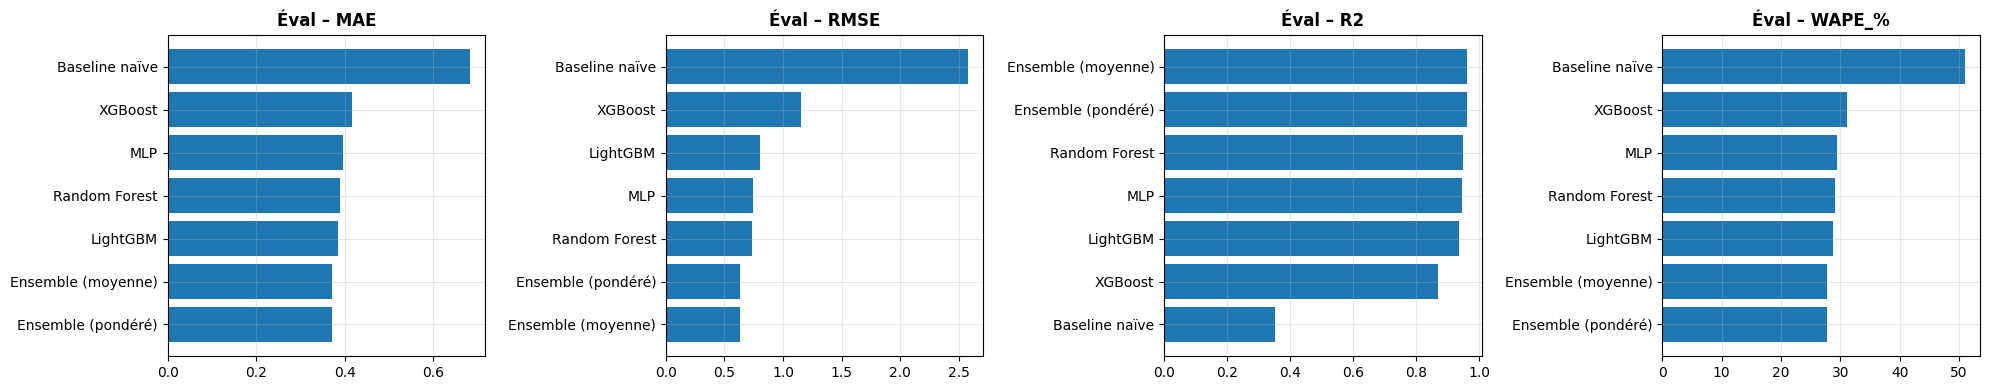

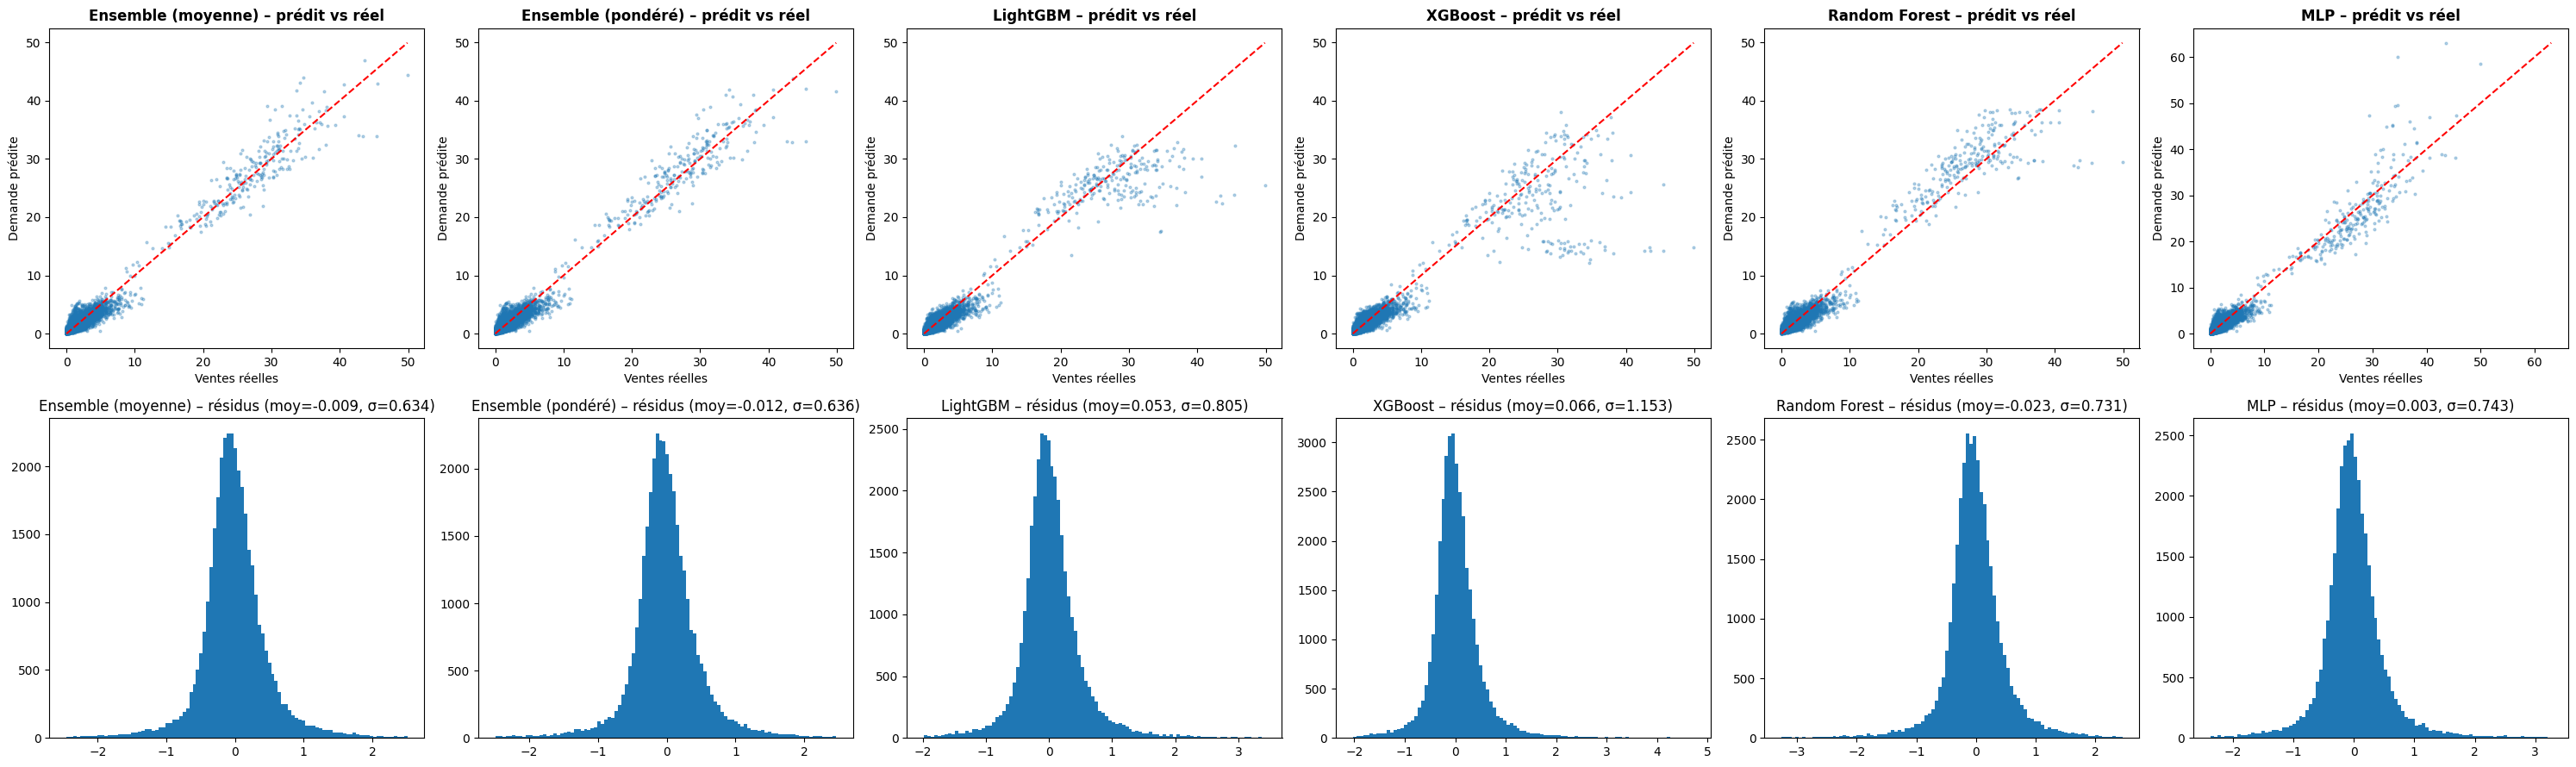

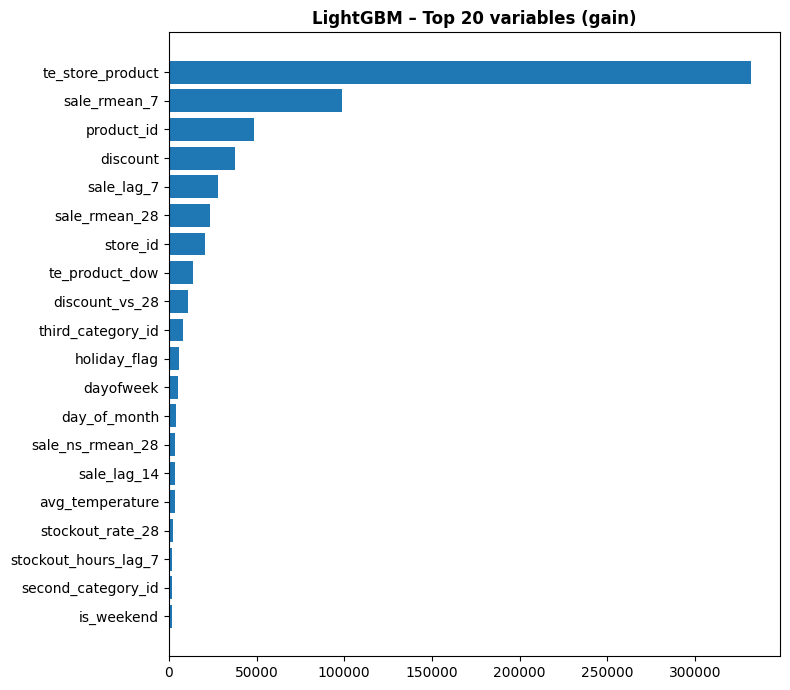

In [29]:
res = pd.DataFrame(results).set_index("Modèle")
show = ["val_MAE", "val_RMSE", "val_R2", "val_WAPE_%", "eval_MAE", "eval_RMSE", "eval_R2", "eval_WAPE_%", "eval_Biais_%", "Temps_s", "Info"]
print("=== RÉSULTATS (éval = jours sans rupture de la semaine suivant la coupure) ===")
print(res[show].sort_values("eval_MAE").round(4).to_string())

base_mae = res.loc["Baseline naïve", "eval_MAE"]
print("\nGain de MAE vs baseline naïve :")
for m in res.index.drop("Baseline naïve"):
    print(f"  {m:14s}: {100*(1 - res.loc[m, 'eval_MAE']/base_mae):+.1f}%")

# Barres : métriques sur l'éval
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, met in zip(axes, ["eval_MAE", "eval_RMSE", "eval_R2", "eval_WAPE_%"]):
    s = res[met].sort_values()
    ax.barh(s.index, s.values)
    ax.set_title(met.replace("eval_", "Éval – "), fontweight="bold")
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# Prédit vs réel et distribution des résidus (même échantillon pour tous les modèles)
models_ml = [m for m in res.index if m != "Baseline naïve"]
rng = np.random.default_rng(SEED)
idx = rng.choice(len(eval_set), size=min(20000, len(eval_set)), replace=False)
y_true = eval_set[TARGET].to_numpy()
fig, axes = plt.subplots(2, len(models_ml), figsize=(5 * len(models_ml), 9))
for j, m in enumerate(models_ml):
    p = preds[m]["eval"]
    lim = max(y_true[idx].max(), p[idx].max())
    axes[0, j].scatter(y_true[idx], p[idx], s=4, alpha=0.3)
    axes[0, j].plot([0, lim], [0, lim], "r--")
    axes[0, j].set_title(f"{m} – prédit vs réel", fontweight="bold")
    axes[0, j].set_xlabel("Ventes réelles"); axes[0, j].set_ylabel("Demande prédite")
    r = y_true - p
    axes[1, j].hist(r, bins=100, range=(np.percentile(r, 0.5), np.percentile(r, 99.5)))
    axes[1, j].set_title(f"{m} – résidus (moy={r.mean():.3f}, σ={r.std():.3f})")
plt.tight_layout(); plt.show()

# Importance des variables (LightGBM, gain)
imp = pd.Series(lgb_final.booster_.feature_importance("gain"), index=FEATURES).sort_values().tail(20)
plt.figure(figsize=(8, 7)); plt.barh(imp.index, imp.values)
plt.title("LightGBM – Top 20 variables (gain)", fontweight="bold"); plt.tight_layout(); plt.show()

**Diagnostic sur les jours en rupture (demande censurée)**

Les jours en rupture, la vraie demande est inconnue : on sait seulement qu'elle est **au moins égale** aux ventes observées. Ce n'est donc pas une métrique de précision. On vérifie simplement qu'un bon modèle de demande prédit des valeurs **supérieures ou égales** aux ventes ces jours-là, et on mesure de combien.

In [30]:
y_so = eval_so_set[TARGET].to_numpy()
rows = []
for m in res.index:
    p = preds[m]["eval_so"]
    rows.append({"Modèle": m,
                 "% jours où prédit >= ventes": 100 * np.mean(p >= y_so),
                 "Demande perdue estimée (somme prédit - ventes, si >0)": np.clip(p - y_so, 0, None).sum(),
                 "Ratio total prédit / ventes": p.sum() / max(y_so.sum(), 1e-9)})
print(f"Jours en rupture dans l'éval : {len(eval_so_set):,}")
print(pd.DataFrame(rows).set_index("Modèle").round(3).to_string())

Jours en rupture dans l'éval : 46,244
                    % jours où prédit >= ventes  Demande perdue estimée (somme prédit - ventes, si >0)  Ratio total prédit / ventes
Modèle                                                                                                                             
Ensemble (moyenne)                       49.587                                              11657.999                        1.062
Ensemble (pondéré)                       49.641                                              11711.107                        1.063
Baseline naïve                           52.091                                              13532.675                        0.908
LightGBM                                 45.980                                              10591.950                        1.004
XGBoost                                  47.956                                              10799.618                        1.000
Random Forest                         

**Lecture des résultats**

- Les modèles sont comparés **à protocole égal**. Les écarts de MAE / RMSE / WAPE sur l'éval viennent donc du modèle, et non plus des variables ou du découpage.
- Les scores sont probablement **plus bas que dans la version précédente**. C'est attendu : l'ancienne version utilisait les ventes de la semaine d'éval (moyennes par produit/magasin, `lag_1`), ce qui gonflait artificiellement les résultats.
- La baseline naïve sert de référence : un modèle n'a d'intérêt que s'il fait clairement mieux qu'elle.
- Pour une prévision à J+1 seulement (réapprovisionnement quotidien), passer `HORIZON = 1` : les lags de 1 à 6 jours deviennent alors autorisés.

### Option A : entraîner sur tous les jours, prédire le scénario « sans rupture »

Jusqu'ici, on n'entraîne que sur les jours sans rupture (ventes = demande) et on jette tous les autres.
L'option A garde **tous les jours** du train :

* **Entraînement** : cible = ventes observées, et on ajoute la rupture **du jour même** (`so_hours_today` = nombre d'heures en rupture, `so_flag_today` = rupture oui/non). Le modèle apprend ainsi combien une rupture fait baisser les ventes.
* **Prédiction** : on met `so_hours_today = 0` et `so_flag_today = 0`. On demande donc au modèle : *« combien aurait-on vendu sans rupture ? »*, c'est-à-dire la demande.
* **Validation et éval inchangées** : jours sans rupture uniquement (là où la vraie demande est connue), même split temporel, mêmes métriques, même facteur de correction k appris sur la validation. Les résultats sont donc directement comparables à ceux du dessus.

Limite : les ruptures arrivent souvent les jours de forte demande ; le modèle peut confondre « forte demande » et « rupture ». Le diagnostic à la fin vérifie que l'effet appris va dans le bon sens.

In [31]:
# ============================================
# OPTION A — PRÉPARATION : tous les jours du train + rupture du jour en variable
# ============================================
RUN_RF_A = True   # Random Forest sur ~2x plus de lignes : ~45-50 min sur Colab. Mettre True pour l'inclure.

SO_FEATURES = ["so_hours_today", "so_flag_today"]
NUM_FEATURES_A = NUM_FEATURES + SO_FEATURES
FEATURES_A = CAT_FEATURES + NUM_FEATURES_A

def add_so_today(df, scenario_no_stockout):
    # Entraînement : rupture réelle du jour. Prédiction : scénario « aucune rupture » (= demande).
    df = df.copy()
    if scenario_no_stockout:
        df["so_hours_today"] = np.float32(0)
        df["so_flag_today"] = np.int8(0)
    else:
        df["so_hours_today"] = df["stockout_hours"].astype("float32")
        df["so_flag_today"] = (df["stockout_hours"] > 0).astype("int8")
    return df

fitA_raw  = panel[panel["set"] == "fit"].copy()                  # TOUS les jours (avec et sans rupture)
fullA_raw = panel[panel["set"].isin(["fit", "val"])].copy()      # TOUS les jours du train complet
print(f"Option A — fit           : {len(fitA_raw):>9,} lignes (vs {len(fit_raw):,} sans rupture)")
print(f"Option A — train complet : {len(fullA_raw):>9,} lignes (vs {len(full_raw):,} sans rupture)")
print(f"Part des jours en rupture dans le train complet : {100 * (1 - fullA_raw['no_stockout'].mean()):.1f}%")

# Même prétraitement (target encoding out-of-fold, médianes) appris sur le seul train ;
# validation et éval = mêmes lignes sans rupture qu'avant.
t0 = time.time()
fitA_set, (valA_set,) = prepare(fitA_raw, [val_raw])
fullA_set, (evalA_set, evalA_so_set) = prepare(fullA_raw, [eval_raw, eval_so_raw])
fitA_set, fullA_set = add_so_today(fitA_set, False), add_so_today(fullA_set, False)
valA_set, evalA_set, evalA_so_set = (add_so_today(d, True) for d in (valA_set, evalA_set, evalA_so_set))
evalA_so_real = add_so_today(evalA_so_set, False)   # jours en rupture avec leur rupture réelle (diagnostic)
print(f"Prétraitement Option A terminé en {time.time()-t0:.0f}s | {len(FEATURES_A)} variables")

yA_fit, yA_val, yA_full = (np.log1p(d[TARGET].to_numpy()) for d in (fitA_set, valA_set, fullA_set))
assert np.allclose(valA_set[TARGET].to_numpy(), val_set[TARGET].to_numpy()), "Validation différente de la version de base"
assert np.allclose(evalA_set[TARGET].to_numpy(), eval_set[TARGET].to_numpy()), "Éval différente de la version de base"

def to_tree_cat_A(df):
    X = df[FEATURES_A].copy()
    for c in CAT_FEATURES:
        X[c] = pd.Categorical(X[c], categories=CAT_LEVELS[c])
    return X

def to_tree_ord_A(df):
    return df[FEATURES_A].astype("float32")

def make_mlp_preprocessor_A():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
                              ("num", StandardScaler(), NUM_FEATURES_A)])

Option A — fit           :   904,096 lignes (vs 355,508 sans rupture)
Option A — train complet :   987,368 lignes (vs 389,839 sans rupture)
Part des jours en rupture dans le train complet : 60.5%
Prétraitement Option A terminé en 11s | 36 variables


In [32]:
# ============================================
# OPTION A — LightGBM (même grille, même early stopping)
# ============================================
t0 = time.time()
XfA, XvA = to_tree_cat_A(fitA_set), to_tree_cat_A(valA_set)
best = None
for mcs in LGB_GRID["min_child_samples"]:
    m = lgb.LGBMRegressor(**LGB_BASE, min_child_samples=mcs)
    m.fit(XfA, yA_fit, eval_set=[(XvA, yA_val)], callbacks=[lgb.early_stopping(100, verbose=False)])
    p = inv(m.predict(XvA))
    mae, rmse = mean_absolute_error(valA_set[TARGET], p), np.sqrt(mean_squared_error(valA_set[TARGET], p))
    print(f"  min_child_samples={mcs:4d} -> val MAE={mae:.4f} RMSE={rmse:.4f} ({m.best_iteration_} arbres)")
    if best is None or mae < best["mae"]:
        best = {"mae": mae, "mcs": mcs, "it": m.best_iteration_, "pred": p}

lgbA_final = lgb.LGBMRegressor(**{**LGB_BASE, "min_child_samples": best["mcs"], "n_estimators": best["it"]})
lgbA_final.fit(to_tree_cat_A(fullA_set), yA_full)
record("LightGBM (A)", best["pred"], inv(lgbA_final.predict(to_tree_cat_A(evalA_set))),
       inv(lgbA_final.predict(to_tree_cat_A(evalA_so_set))), time.time() - t0,
       f"Option A, {best['it']} arbres, min_child_samples={best['mcs']}")
preds["LightGBM (A)"]["eval_so_real"] = inv(lgbA_final.predict(to_tree_cat_A(evalA_so_real)))
del XfA, XvA, m; gc.collect()

  min_child_samples=  10 -> val MAE=0.3455 RMSE=0.5753 (934 arbres)
  min_child_samples=  30 -> val MAE=0.3457 RMSE=0.5750 (1005 arbres)
  min_child_samples= 100 -> val MAE=0.3448 RMSE=0.5720 (875 arbres)
LightGBM (A)   | VAL  MAE=0.3448 RMSE=0.5720 R²=0.9288 | facteur k=1.094
               | EVAL brut    MAE=0.3849 RMSE=0.7815 Biais=-11.1%
               | EVAL corrigé MAE=0.3699 RMSE=0.6915 R²=0.9535 WAPE=27.6% Biais=-2.8%  (Option A, 875 arbres, min_child_samples=100)


52759

In [33]:
# ============================================
# OPTION A — XGBoost
# ============================================
t0 = time.time()
xgbA_val = xgb.XGBRegressor(**XGB_PARAMS, early_stopping_rounds=100)
xgbA_val.fit(to_tree_cat_A(fitA_set), yA_fit, eval_set=[(to_tree_cat_A(valA_set), yA_val)], verbose=False)
xgbA_best_it = xgbA_val.best_iteration + 1
val_pred = inv(xgbA_val.predict(to_tree_cat_A(valA_set), iteration_range=(0, xgbA_best_it)))
del xgbA_val; gc.collect()

xgbA_final = xgb.XGBRegressor(**{**XGB_PARAMS, "n_estimators": xgbA_best_it})
xgbA_final.fit(to_tree_cat_A(fullA_set), yA_full, verbose=False)
record("XGBoost (A)", val_pred, inv(xgbA_final.predict(to_tree_cat_A(evalA_set))),
       inv(xgbA_final.predict(to_tree_cat_A(evalA_so_set))), time.time() - t0, f"Option A, {xgbA_best_it} arbres")
preds["XGBoost (A)"]["eval_so_real"] = inv(xgbA_final.predict(to_tree_cat_A(evalA_so_real)))

XGBoost (A)    | VAL  MAE=0.3428 RMSE=0.5675 R²=0.9299 | facteur k=1.094
               | EVAL brut    MAE=0.3883 RMSE=0.8056 Biais=-11.2%
               | EVAL corrigé MAE=0.3727 RMSE=0.7061 R²=0.9515 WAPE=27.8% Biais=-2.9%  (Option A, 826 arbres)


In [34]:
# ============================================
# OPTION A — Random Forest (long : activer avec RUN_RF_A = True)
# ============================================
if RUN_RF_A:
    t0 = time.time()
    rfA_val = RandomForestRegressor(**RF_PARAMS).fit(to_tree_ord_A(fitA_set), yA_fit)
    val_pred = inv(rfA_val.predict(to_tree_ord_A(valA_set)))
    del rfA_val; gc.collect()
    rfA_final = RandomForestRegressor(**RF_PARAMS).fit(to_tree_ord_A(fullA_set), yA_full)
    record("Random Forest (A)", val_pred, inv(rfA_final.predict(to_tree_ord_A(evalA_set))),
           inv(rfA_final.predict(to_tree_ord_A(evalA_so_set))), time.time() - t0,
           f"Option A, {RF_PARAMS['n_estimators']} arbres")
    preds["Random Forest (A)"]["eval_so_real"] = inv(rfA_final.predict(to_tree_ord_A(evalA_so_real)))
    del rfA_final; gc.collect()
else:
    print("Random Forest (A) ignoré (RUN_RF_A = False).")

Random Forest (A) | VAL  MAE=0.3610 RMSE=0.6054 R²=0.9202 | facteur k=1.104
               | EVAL brut    MAE=0.3859 RMSE=0.7368 Biais=-8.4%
               | EVAL corrigé MAE=0.3862 RMSE=0.7090 R²=0.9511 WAPE=28.8% Biais=+1.1%  (Option A, 300 arbres)


In [35]:
# ============================================
# OPTION A — MLP (même architecture, même early stopping)
# ============================================
t0 = time.time()
preA_val = make_mlp_preprocessor_A().fit(fitA_set[FEATURES_A])
XvA = preA_val.transform(valA_set[FEATURES_A])
mlpA_val, mlpA_best_ep = train_mlp(preA_val.transform(fitA_set[FEATURES_A]), yA_fit, 40, XvA, yA_val)
val_pred = inv(mlpA_val.predict(XvA))
del mlpA_val, XvA; gc.collect()

preA_final = make_mlp_preprocessor_A().fit(fullA_set[FEATURES_A])
mlpA_final, _ = train_mlp(preA_final.transform(fullA_set[FEATURES_A]), yA_full, mlpA_best_ep)
record("MLP (A)", val_pred, inv(mlpA_final.predict(preA_final.transform(evalA_set[FEATURES_A]))),
       inv(mlpA_final.predict(preA_final.transform(evalA_so_set[FEATURES_A]))), time.time() - t0,
       f"Option A, {mlpA_best_ep} époques")
preds["MLP (A)"]["eval_so_real"] = inv(mlpA_final.predict(preA_final.transform(evalA_so_real[FEATURES_A])))

MLP (A)        | VAL  MAE=0.3543 RMSE=0.5990 R²=0.9219 | facteur k=1.108
               | EVAL brut    MAE=0.5026 RMSE=1.8219 Biais=+11.3%
               | EVAL corrigé MAE=0.5754 RMSE=2.2885 R²=0.4906 WAPE=43.0% Biais=+23.4%  (Option A, 1 époques)


### Option A — CatBoost et ensemble

* **CatBoost** : même famille que LightGBM / XGBoost (gradient boosting), avec un traitement natif des variables catégorielles à forte cardinalité (`product_id`, `store_id`…). Même protocole : early stopping sur la validation, réentraînement sur tout le train, même cible, même correction k.
* **Ensemble** : moyenne des prédictions de plusieurs modèles. Les modèles ne se trompent pas de la même façon, donc la moyenne est souvent meilleure que le meilleur modèle seul. Deux versions : moyenne simple, et moyenne pondérée dont les poids sont choisis **sur la validation uniquement** (aucune information de l'éval). Le MLP (A) est exclu car instable.

In [36]:
# ============================================
# OPTION A — CatBoost (catégorielles natives, même protocole)
# ============================================
%pip install -q catboost
import shutil
from catboost import CatBoostRegressor

CB_TASK = "GPU" if shutil.which("nvidia-smi") else "CPU"
CB_PARAMS = dict(loss_function="RMSE", eval_metric="RMSE", learning_rate=0.05, depth=8,
                 l2_leaf_reg=3.0, iterations=5000, random_seed=SEED, task_type=CB_TASK,
                 cat_features=CAT_FEATURES, verbose=0)
if CB_TASK == "CPU":
    CB_PARAMS["thread_count"] = -1

def to_cb_A(df):
    X = df[FEATURES_A].copy()
    for c in CAT_FEATURES:
        X[c] = X[c].astype("int64")
    return X

t0 = time.time()
# (a) fit -> validation : nombre d'itérations par early stopping
cbA_val = CatBoostRegressor(**CB_PARAMS, early_stopping_rounds=100)
cbA_val.fit(to_cb_A(fitA_set), yA_fit, eval_set=(to_cb_A(valA_set), yA_val), use_best_model=True)
cbA_best_it = cbA_val.get_best_iteration() + 1
val_pred = inv(cbA_val.predict(to_cb_A(valA_set)))
del cbA_val; gc.collect()

# (b) réentraînement sur tout le train -> éval
cbA_final = CatBoostRegressor(**{**CB_PARAMS, "iterations": cbA_best_it})
cbA_final.fit(to_cb_A(fullA_set), yA_full)
record("CatBoost (A)", val_pred, inv(cbA_final.predict(to_cb_A(evalA_set))),
       inv(cbA_final.predict(to_cb_A(evalA_so_set))), time.time() - t0,
       f"Option A, {cbA_best_it} itérations, {CB_TASK}")
preds["CatBoost (A)"]["eval_so_real"] = inv(cbA_final.predict(to_cb_A(evalA_so_real)))

error: externally-managed-environment

× This environment is externally managed
╰─> This Python installation is managed by uv and should not be modified.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.


Note: you may need to restart the kernel to use updated packages.
CatBoost (A)   | VAL  MAE=0.3393 RMSE=0.5425 R²=0.9359 | facteur k=1.073
               | EVAL brut    MAE=0.3801 RMSE=0.7538 Biais=-10.8%
               | EVAL corrigé MAE=0.3666 RMSE=0.6784 R²=0.9552 WAPE=27.4% Biais=-4.4%  (Option A, 2113 itérations, CPU)


In [37]:
# ============================================
# ENSEMBLE : moyenne des meilleurs modèles (poids choisis sur la VALIDATION uniquement)
# ============================================
from scipy.optimize import minimize

# MLP (A) exclu : instable (1 époque, très mauvais sur l'éval malgré une bonne validation)
ENS_CANDIDATES = ["LightGBM (A)", "XGBoost (A)", "CatBoost (A)", "Random Forest (A)", "Random Forest", "MLP"]
# Seuls les modèles dont les prédictions correspondent au split actuel sont retenus
members = [m for m in ENS_CANDIDATES if m in preds and "val" in preds[m]
           and len(preds[m]["val"]) == len(val_set)
           and len(preds[m]["eval_brut"]) == len(eval_set)
           and len(preds[m]["eval_so_brut"]) == len(eval_so_set)]
print("Membres de l'ensemble :", members)
missing = [m for m in ENS_CANDIDATES if m not in members]
if missing:
    print("Absents (cellule non exécutée ou prédictions effacées) :", missing)
no_val = [m for m in ENS_CANDIDATES if m in preds and "val" not in preds[m]]
if no_val:
    print("Enregistrés SANS prédictions de validation (ancienne fonction record) :", no_val)
    print("-> exécutez la cellule 'MÉTRIQUES COMMUNES + CORRECTION DU BIAIS', puis ré-entraînez ces modèles.")
if len(members) < 2:
    raise RuntimeError(
        f"Ensemble impossible : {len(members)} modèle(s) disponible(s) dans preds. "
        "Ré-exécutez d'abord les cellules des modèles (Random Forest, MLP, LightGBM/XGBoost/RF/CatBoost (A)).")

y_val_true = val_set[TARGET].to_numpy()
V  = np.column_stack([preds[m]["val"] for m in members])            # validation (prédictions brutes)
E  = np.column_stack([preds[m]["eval_brut"] for m in members])      # éval (prédictions brutes)
ES = np.column_stack([preds[m]["eval_so_brut"] for m in members])   # jours en rupture de l'éval

# (a) Moyenne simple
w_eq = np.full(len(members), 1 / len(members))
record("Ensemble (moyenne)", V @ w_eq, E @ w_eq, ES @ w_eq, 0.0, "moyenne de " + ", ".join(members))

# (b) Poids optimisés sur la MAE de validation (positifs, somme = 1)
def val_mae(w):
    w = np.abs(w) / np.abs(w).sum()
    return mean_absolute_error(y_val_true, V @ w)

opt = minimize(val_mae, w_eq, method="Nelder-Mead", options={"maxiter": 4000, "xatol": 1e-4, "fatol": 1e-7})
w_opt = np.abs(opt.x) / np.abs(opt.x).sum()
weights_txt = ", ".join(f"{m}={w:.2f}" for m, w in zip(members, w_opt))
print("Poids optimisés sur la validation :", weights_txt)
record("Ensemble (pondéré)", V @ w_opt, E @ w_opt, ES @ w_opt, 0.0, weights_txt)

Membres de l'ensemble : ['LightGBM (A)', 'XGBoost (A)', 'CatBoost (A)', 'Random Forest (A)', 'Random Forest', 'MLP']
Ensemble (moyenne) | VAL  MAE=0.3398 RMSE=0.5373 R²=0.9371 | facteur k=1.083
               | EVAL brut    MAE=0.3715 RMSE=0.6999 Biais=-8.8%
               | EVAL corrigé MAE=0.3620 RMSE=0.6351 R²=0.9608 WAPE=27.0% Biais=-1.2%  (moyenne de LightGBM (A), XGBoost (A), CatBoost (A), Random Forest (A), Random Forest, MLP)
Poids optimisés sur la validation : LightGBM (A)=0.00, XGBoost (A)=0.35, CatBoost (A)=0.43, Random Forest (A)=0.01, Random Forest=0.00, MLP=0.22
Ensemble (pondéré) | VAL  MAE=0.3346 RMSE=0.5205 R²=0.9410 | facteur k=1.071
               | EVAL brut    MAE=0.3733 RMSE=0.7163 Biais=-9.4%
               | EVAL corrigé MAE=0.3611 RMSE=0.6401 R²=0.9601 WAPE=27.0% Biais=-2.9%  (LightGBM (A)=0.00, XGBoost (A)=0.35, CatBoost (A)=0.43, Random Forest (A)=0.01, Random Forest=0.00, MLP=0.22)


In [38]:
# ============================================
# COMPARAISON : version de base vs Option A (même validation, même éval)
# ============================================
res = pd.DataFrame(results).set_index("Modèle")
cols = ["val_MAE", "eval_MAE", "eval_RMSE", "eval_R2", "eval_WAPE_%", "eval_Biais_%",
        "eval_brut_Biais_%", "facteur_k", "Temps_s"]
rows = []
for base in ["LightGBM", "XGBoost", "CatBoost", "Random Forest", "MLP"]:
    for m in (base, f"{base} (A)"):
        if m in res.index:
            rows.append(res.loc[m, cols].rename(m))
rows += [res.loc[m, cols].rename(m) for m in res.index if m.startswith("Ensemble")]
cmp = pd.DataFrame(rows)
print("=== ÉVAL (jours sans rupture, après correction k) : base vs Option A ===")
print(cmp.round(4).to_string())

print("\nVariation de MAE d'éval avec l'Option A (négatif = mieux) :")
for base in ["LightGBM", "XGBoost", "CatBoost", "Random Forest", "MLP"]:
    if base in res.index and f"{base} (A)" in res.index:
        d = 100 * (res.loc[f"{base} (A)", "eval_MAE"] / res.loc[base, "eval_MAE"] - 1)
        print(f"  {base:14s}: {d:+.1f}%")

# Diagnostic jours en rupture : la demande prédite doit dépasser les ventes observées
y_so = eval_so_set[TARGET].to_numpy()
rows = []
for m in res.index:
    p = preds[m]["eval_so"]
    row = {"Modèle": m,
           "% jours prédit >= ventes": 100 * np.mean(p >= y_so),
           "Ratio prédit / ventes": p.sum() / max(y_so.sum(), 1e-9)}
    if "eval_so_real" in preds[m]:
        # Même modèle, avec la rupture réelle du jour : doit être PLUS BAS que le scénario sans rupture
        row["Ratio scénario sans rupture / avec rupture réelle"] = p.sum() / max(preds[m]["eval_so_real"].sum() * res.loc[m, "facteur_k"], 1e-9)
    rows.append(row)
print(f"\n=== Jours en rupture de l'éval ({len(y_so):,}) ===")
print(pd.DataFrame(rows).set_index("Modèle").round(3).to_string())

if "lgbA_final" in globals() and "evalA_so_set" in globals():
    # Effet appris de la rupture (LightGBM A) : demande prédite selon le nombre d'heures en rupture fixé
    sample = evalA_so_set.sample(n=min(5000, len(evalA_so_set)), random_state=SEED)
    effect = {}
    for h in [0, 2, 4, 8, 12, 16]:
        s = sample.copy(); s["so_hours_today"] = np.float32(h); s["so_flag_today"] = np.int8(h > 0)
        effect[h] = inv(lgbA_final.predict(to_tree_cat_A(s))).mean()
    print("\nLightGBM (A) — ventes moyennes prédites si on fixe la rupture du jour à h heures :")
    print("  " + " | ".join(f"h={h}: {v:.3f}" for h, v in effect.items()))
    print("  (doit baisser quand h augmente : sinon le modèle confond rupture et forte demande)")
else:
    print("\n(Effet de la rupture non calculé : exécutez d'abord les cellules OPTION A — PRÉPARATION et OPTION A — LightGBM.)")


=== ÉVAL (jours sans rupture, après correction k) : base vs Option A ===
                    val_MAE  eval_MAE  eval_RMSE  eval_R2  eval_WAPE_%  eval_Biais_%  eval_brut_Biais_%  facteur_k    Temps_s
LightGBM             0.3509    0.3844     0.8065   0.9367      28.7045       -3.9629           -11.8980     1.0901    99.0979
LightGBM (A)         0.3448    0.3699     0.6915   0.9535      27.6214       -2.7804           -11.1320     1.0940   295.1359
XGBoost              0.3586    0.4170     1.1548   0.8703      31.1380       -4.9404           -13.7582     1.1022   128.7490
XGBoost (A)          0.3428    0.3727     0.7061   0.9515      27.8318       -2.8763           -11.1867     1.0936   435.1182
CatBoost (A)         0.3393    0.3666     0.6784   0.9552      27.3786       -4.3542           -10.8220     1.0725  5581.2248
Random Forest        0.3628    0.3894     0.7313   0.9480      29.0798        1.6853            -7.7855     1.1027   523.4757
Random Forest (A)    0.3610    0.3862     0.7

### Amélioration : contrainte monotone + plancher `max(prédiction, ventes)`

Le diagnostic ci-dessus montre que LightGBM (A) prédit **plus** de ventes avec 2–8 h de rupture qu'avec 0 h : il confond « rupture courte » et « forte demande ». Le scénario « sans rupture » sous-estime alors la demande latente.

Deux corrections :

1. **Contrainte monotone** : on impose au modèle que plus d'heures de rupture (`so_hours_today`, `so_flag_today`) ne peut **jamais augmenter** les ventes prédites (`monotone_constraints = -1`). Même protocole qu'avant : même grille, early stopping sur la validation, réentraînement sur tout le train, même correction k.
2. **Plancher** : un jour en rupture, la demande réelle est au moins égale aux ventes observées. Demande latente = `max(prédiction, ventes)`.

Les métriques sur les jours **sans** rupture restent directement comparables aux autres modèles ; l'apport principal se lit sur les jours **en** rupture.


In [39]:
# ============================================
# AMÉLIORATION — LightGBM (A) monotone + plancher max(prédiction, ventes)
# ============================================
t0 = time.time()
NAME_M = "LightGBM (A, monotone)"
H_TEST = [0, 2, 4, 8, 12, 16]

# 1) Contrainte monotone : plus de rupture => ventes prédites plus faibles (ou égales), jamais plus fortes
MONO = {"so_hours_today": -1, "so_flag_today": -1}
LGB_MONO = {**LGB_BASE,
            "monotone_constraints": [MONO.get(c, 0) for c in FEATURES_A],
            "monotone_constraints_method": "intermediate"}

XfA, XvA = to_tree_cat_A(fitA_set), to_tree_cat_A(valA_set)
best_m = None
for mcs in LGB_GRID["min_child_samples"]:
    m = lgb.LGBMRegressor(**LGB_MONO, min_child_samples=mcs)
    m.fit(XfA, yA_fit, eval_set=[(XvA, yA_val)], callbacks=[lgb.early_stopping(100, verbose=False)])
    p = inv(m.predict(XvA))
    mae, rmse = mean_absolute_error(valA_set[TARGET], p), np.sqrt(mean_squared_error(valA_set[TARGET], p))
    print(f"  min_child_samples={mcs:4d} -> val MAE={mae:.4f} RMSE={rmse:.4f} ({m.best_iteration_} arbres)")
    if best_m is None or mae < best_m["mae"]:
        best_m = {"mae": mae, "mcs": mcs, "it": m.best_iteration_, "pred": p}
del XfA, XvA, m; gc.collect()

lgbM_final = lgb.LGBMRegressor(**{**LGB_MONO, "min_child_samples": best_m["mcs"], "n_estimators": best_m["it"]})
lgbM_final.fit(to_tree_cat_A(fullA_set), yA_full)
record(NAME_M, best_m["pred"], inv(lgbM_final.predict(to_tree_cat_A(evalA_set))),
       inv(lgbM_final.predict(to_tree_cat_A(evalA_so_set))), time.time() - t0,
       f"Option A monotone, {best_m['it']} arbres, min_child_samples={best_m['mcs']}")
preds[NAME_M]["eval_so_real"] = inv(lgbM_final.predict(to_tree_cat_A(evalA_so_real)))

# 2) Vérification : effet de la rupture du jour (doit baisser quand h augmente)
smp = evalA_so_set.sample(n=min(5000, len(evalA_so_set)), random_state=SEED)
print("\nVentes moyennes prédites si on fixe la rupture du jour à h heures :")
for name, mdl in [("LightGBM (A)", lgbA_final), (NAME_M, lgbM_final)]:
    vals = []
    for h in H_TEST:
        s = smp.copy(); s["so_hours_today"] = np.float32(h); s["so_flag_today"] = np.int8(h > 0)
        vals.append(inv(mdl.predict(to_tree_cat_A(s))).mean())
    ok = all(a >= b - 1e-9 for a, b in zip(vals, vals[1:]))
    print(f"  {name:24s}: " + " | ".join(f"h={h}: {v:.3f}" for h, v in zip(H_TEST, vals))
          + ("   -> décroissant OK" if ok else "   -> NON monotone"))

# 3) Précision sur les jours SANS rupture (comparable aux autres modèles)
res = pd.DataFrame(results).set_index("Modèle")
cols = ["val_MAE", "eval_MAE", "eval_RMSE", "eval_R2", "eval_WAPE_%", "eval_Biais_%", "facteur_k"]
show_m = [m for m in ["LightGBM (A)", NAME_M, "CatBoost (A)", "Ensemble (moyenne)"] if m in res.index]
print("\n=== Éval, jours sans rupture (après correction k) ===")
print(res.loc[show_m, cols].round(4).to_string())

# 4) Plancher sur les jours EN rupture : demande latente = max(prédiction, ventes)
y_so = eval_so_set[TARGET].to_numpy()
rows = []
for m in show_m:
    p = preds[m]["eval_so"]                        # prédictions corrigées par k
    p_floor = np.maximum(p, y_so)
    row = {"Modèle": m,
           "% jours relevés par le plancher": 100 * np.mean(p < y_so),
           "Demande/ventes sans plancher": p.sum() / y_so.sum(),
           "Demande/ventes avec plancher": p_floor.sum() / y_so.sum(),
           "Demande perdue (unités)": (p_floor - y_so).sum()}
    if "eval_so_real" in preds[m]:
        row["Scénario sans rupture / rupture réelle"] = p.sum() / max(preds[m]["eval_so_real"].sum() * res.loc[m, "facteur_k"], 1e-9)
    rows.append(row)
print(f"\n=== Jours en rupture de l'éval ({len(y_so):,}) : effet du plancher ===")
print(pd.DataFrame(rows).set_index("Modèle").round(3).to_string())

# 5) Demande latente finale sur la semaine d'éval (modèle monotone + plancher)
latent_eval = pd.concat([
    eval_set[KEYS + ["dt", TARGET]].assign(rupture=0, demande_latente=eval_set[TARGET].to_numpy()),
    eval_so_set[KEYS + ["dt", TARGET]].assign(rupture=1, demande_latente=np.maximum(preds[NAME_M]["eval_so"], y_so)),
]).sort_values(KEYS + ["dt"]).reset_index(drop=True)
tot_sales, tot_latent = latent_eval[TARGET].sum(), latent_eval["demande_latente"].sum()
print(f"\nSemaine d'éval — ventes observées : {tot_sales:,.1f} | demande latente : {tot_latent:,.1f} "
      f"| demande perdue : {tot_latent - tot_sales:,.1f} (+{100 * (tot_latent / tot_sales - 1):.1f} %)")
print(f"Temps total : {time.time() - t0:.0f}s  (tableau complet : latent_eval)")


  min_child_samples=  10 -> val MAE=0.3469 RMSE=0.5884 (669 arbres)
  min_child_samples=  30 -> val MAE=0.3463 RMSE=0.5861 (1050 arbres)
  min_child_samples= 100 -> val MAE=0.3478 RMSE=0.5880 (869 arbres)
LightGBM (A, monotone) | VAL  MAE=0.3463 RMSE=0.5861 R²=0.9252 | facteur k=1.070
               | EVAL brut    MAE=0.3888 RMSE=0.8135 Biais=-9.8%
               | EVAL corrigé MAE=0.3751 RMSE=0.7261 R²=0.9487 WAPE=28.0% Biais=-3.4%  (Option A monotone, 1050 arbres, min_child_samples=30)

Ventes moyennes prédites si on fixe la rupture du jour à h heures :
  LightGBM (A)            : h=0: 1.091 | h=2: 1.122 | h=4: 1.124 | h=8: 1.139 | h=12: 1.038 | h=16: 0.802   -> NON monotone
  LightGBM (A, monotone)  : h=0: 1.115 | h=2: 1.115 | h=4: 1.114 | h=8: 1.100 | h=12: 1.038 | h=16: 0.812   -> décroissant OK

=== Éval, jours sans rupture (après correction k) ===
                        val_MAE  eval_MAE  eval_RMSE  eval_R2  eval_WAPE_%  eval_Biais_%  facteur_k
Modèle                           